[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_AdversarialBounds_Liao2021.ipynb)

# Robust in practice? A numerical verification of the adversarial-robustness bounds of Liao, Convy, Huggins and Whaley (2021)

**Paper.** Haoran Liao, Ian Convy, William J. Huggins and K. Birgitta Whaley, *Robust in Practice: Adversarial Attacks on Quantum Machine Learning*,
Physical Review A 103, 042427 (2021), arXiv:2010.08544, [https://arxiv.org/abs/2010.08544](https://arxiv.org/abs/2010.08544).

> **Read this first: the paper has no experiment.** It is a theory paper. It contains one schematic figure (Fig. 1) and one table of *analytic* bounds (Table I); it states theorems and gives proofs in appendices.
> It has no dataset, no trained model, no accuracy and no measured curve, and its Discussion lists "experimentally compare the adversarial robustness of particular QML models ... with the bounds that we have derived" as future work.
> So there is nothing to "reproduce" in the usual sense. **This notebook is a numerical verification of the paper's analytic claims**: the dataset, the classifiers, the attacks and the generator are choices of the notebook (all marked `# CHOICE:`),
> and every verdict is of the form "bound holds / bound violated" or "scaling direction reproduced / not reproduced", never "table matches".

**What the paper argues.** Liu and Wittek (2020) showed that a quantum classifier on *Haar-random* pure states is exponentially vulnerable in the number of qubits, a consequence of the concentration of measure.
Liao et al. argue that this is not the relevant setting: real data occupy a small, smoothly generated subset of Hilbert space (here: images encoded as product states, with the image drawn from a Gaussian latent space through a smooth generator),
and for that subset the same argument gives only a **mild, polynomial** decrease of the robustness with the number of qubits.

**What this notebook does.**

* Part A (Section 5, Theorem 1 / Corollary 1): Haar-random states, two classifiers, exact closed-form and exact-gradient attacks, `n = 2 ... 8` qubits (`2 ... 10` in the full run). Measures the decay with `n` and compares the empirical risk with the paper's bound.
* Part B (Section 6, Theorem 2): MNIST digit pair, product-state qubit encoding, a PCA-decoder generator whose Lipschitz constant is computed exactly, a trained VQC and two classical baselines (logistic regression, a small MLP) on the same pooled pixels,
  white-box attacks with exact gradients, a gradient-free masking detector, and a comparison with Part A.
* Section 7 (Proposition 1): modulus of continuity of the generator composed with the encoding, checked on tens of thousands of pairs.
* Section 8 (Appendix B): the reverse-circuit attack on a unitary classifier, with inequality (B1) checked exactly.
* Section 9 (Theorem 3): the tomography-plus-refit defence, checked on small instances.
* Section 10: a table of per-claim verdicts, a critical reading, and exercises.

**How to run.** Colab, CPU runtime (no GPU, no account, no token; the MNIST mirror `ylecun/mnist` is public), *Runtime -> Run all*. The outputs stored in this file are from the **full run (`FAST_MODE = False`, about 70 minutes on a shared 4-core laptop CPU)**: qubits 2 to 10 for the Haar part, 1000 Haar states per qubit number, MNIST pooled to up to `n = 9` pixels with 600 training images per class, 250 training steps, 600 generated points per case, and the larger attack and verification budgets listed in the configuration cell.
Set `FAST_MODE = True` for a class demo (qubits 2 to 8, smaller samples; about 7 to 10 minutes). Everything is exact state-vector simulation; `IBM_TOKEN` is not needed because there is no hardware step.

**What you get at the end.** The circuits that were executed, real-data and Haar-state visualisations, the empirical risk curves against the bounds, a per-claim verdict table, and five exercises.

## The paper in one page

* **Setting.** A quantum classifier is a quantum channel with POVMs `{Pi_l}`; confidence of label `l` is `tr(E(rho) Pi_l)`. The distance between states is the trace distance; the confidence cannot change by more than the trace distance (Appendix A), so an attacker either moves a state minimally across the boundary or maximises the confidence change within a budget.
  Two attack types: *error-region* (needs ground truth) and *prediction-change* (needs only `h`); the paper uses the second.
* **Definitions.** `R^PC_eps(h, mu) = Pr_{x ~ mu}[ exists x' in B_eps(x): h(x') != h(x) ]`. *Robustness* = the size of `eps` needed for the risk to exceed a constant. *In-distribution* attacks stay on the data manifold `S`, *unconstrained* attacks do not.
* **Encoding (Eq. 1, 2).** An image `u in [0,1]^n` becomes the product state `(x)_i [cos(pi u_i/2)|0> + sin(pi u_i/2)|1>]` (qudits for `d > 2`). Amplitude encoding is explicitly not considered.
* **Theorem 1 / Corollary 1 (Haar-random states).** For any classifier with no class of measure above `1 - eta`: `R^PC_eps <= 1 - gamma` implies `||U - V||_2 <= sqrt(4/N) lambda_1`, and in trace norm `||rho - sigma||_1 <= 4 N^-1 lambda_1 = Omega(d^-n)`,
  with `lambda_1 = sqrt(ln(2 sqrt2 / eta)) + sqrt(ln(2 sqrt2 / gamma))`, `N = d^n`: **exponential vulnerability**. The paper argues this is "not of practical interest" because Haar-random states are not real data.
* **Proposition 1.** If `g1: Z -> I` (Gaussian latent to `n`-pixel image) has modulus of continuity `omega_1`, then `g = g2 o g1` has `omega(tau) >= sqrt(1 - cos^{2n(d-1)}(pi omega_1(tau)/(2n)))`, i.e. `Omega(sqrt(d/n))` when `omega_1 = Omega(1)`.
* **Theorem 2 (in-distribution).** For classes of measure `<= 1/2`: `R^PC_{eps_in} <= 1 - gamma` implies `eps_in <= omega( sqrt(ln(pi / (2 gamma^2))) )` (Gaussian isoperimetric inequality in the latent space). With a Lipschitz generator: robustness `O(sqrt(1/n))` in the trace norm, **mildly polynomial**.
  The bound is attained only for classifiers that are linear in the latent space; more equiprobable classes make it worse.
* **Theorem 3 (unconstrained attacks; a defence).** Single-qubit tomography of the input followed by a numerical fit of the nearest encoded product state gives `2 - 2(1 - eps_in^2/16)^{1/n_e} <= eps_unc <= eps_in`.
* **Appendix B.** A reversible (unitary) classifier can be run backwards from a target class to create an attack state; replacing an `eps`-portion of the samples succeeds iff `eps > 1 - 1/(1 + 2 delta)` (B1).
* **Claims in the abstract.** (i) Haar-random: exponentially decreasing robustness; (ii) smoothly generated states: only mildly polynomial decrease, `O(1/sqrt(n))` in trace norm; (iii) hence QML can be useful in real tasks.
* **Numbers in the paper.** None (no measured values). The only formulas with numbers are Table I (`Omega(d^-n)`, `Omega(d^{-n} 2 sqrt(n))`, `Omega(sqrt(d/n))`).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Experiment, data, classifier | none (theory) | `# CHOICE:` everything below |
| Dataset | MNIST only as an illustration ("a digit 0 or 1") | `# CHOICE:` real MNIST digits 0 and 1 (`ylecun/mnist`, public); `N_TRAIN_PER_CLASS` train images per class from the official train split, `N_TEST_PER_CLASS` from the test split |
| Number of pixels / qubits | `n` pixels = `n` qubits, any `n` | `# CHOICE:` the 28x28 image is average-pooled to a grid of `n` blocks (1x2, 1x3, 2x2, 2x3, 2x4; plus 3x3 in the full run); each pooled pixel is min-max scaled to `[0,1]` with training statistics only |
| Encoding | product state, Eq. (1), `d = 2` (amplitude encoding not considered) | the same product encoding `RY(pi u_i)`. (Amplitude encoding would need the bounds re-derived; it is therefore not used) |
| Generator `g1` | any smooth generator (normalizing flow, GAN decoder); Lipschitz constant not computed | `# CHOICE:` the PCA/PPCA decoder `clip(mu + L z, 0, 1)` with latent dimension `m = n`; its modulus `omega_1(tau) <= ||L||_{2->1} tau` is computed **exactly** by enumerating sign vectors |
| Generator scale | `omega_1 = Omega(1)` assumed | two scales: "natural" (as fitted) and "paper-regime" (contrast shrunk so that `||L||_{2->1}` stays at its value at the smallest `n`) |
| Classifier | "any quantum classifier" | `# CHOICE:` `RY` layers + a CNOT chain + `<Z>` on the last qubit (`VQC_REPS = 3`), trained with Adam on the cross-entropy of `kappa (f - b)`; baselines on the same pooled pixels: logistic regression and an MLP with 16 tanh units |
| Decision threshold | POVM at 1/2 | the threshold of every model is placed at the median of its score over generated latents, so that both classes have measure exactly `1/2` under the generated distribution (the hypothesis of Theorem 2) |
| Haar part | any classifier, `eta` from the class measures | `# CHOICE:` two fixed classifiers: a Haar-random projective measurement `K1` and a random-weight VQC `K2` (`HAAR_REPS = 6`); both are balanced, `eta = 1/2` |
| Attack | exists-style definition, no algorithm | Haar: closed-form optimum (derived and validated) plus exact-gradient DeepFool; generated: DeepFool, shrinking-radius PGD, a boundary walk on the trace distance, and a gradient-free random-direction search as a masking detector |
| Modulus `omega` in Eq. (7) | tight modulus, lower bounded by Prop. 1 | both the Proposition 1 form and a rigorous worst-case modulus `omega_sup` are used |
| Tomography fit in Theorem 3 | "numerically fit the pixel values" | `# CHOICE:` L-BFGS-B on the trace-norm distance, started from the Bloch vectors of the single-qubit marginals |
| Hardware | none | none (`IBM_TOKEN` unused) |
| Seeds | n/a | `SEED = 42` for every random generator |

**Tolerances.** The paper gives no numbers, so the "2 points / 0.02" rule of the factory does not apply; the verdicts below are exact inequalities checked with a Monte-Carlo tolerance of two standard errors, and fitted exponents are compared with the paper's stated exponents within 0.02 (rate per qubit).

## 1. Setup: install, configuration, imports

The install cell is pinned to the versions used for the executed run and is skipped when the packages are already importable.
PennyLane is used for the **circuit drawings and as the reference implementation**; the verification loops run on a small exact
NumPy state-vector simulator written for this notebook (thousands of attacks with exact gradients would take hours through a
QNode on a CPU). Section 2 asserts that the NumPy simulator and the PennyLane QNode agree to machine precision (values,
unitary matrix and gradients), so every number below is a number of the drawn circuit.

In [1]:
# Installs (pinned to the versions this notebook was executed with). Skipped when already importable.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane as _qml
    _have = _qml.__version__ == "0.45.1"
except Exception:
    _have = False
try:
    import pylatexenc  # noqa: F401  (not needed for PennyLane drawings; harmless)
except Exception:
    pass
if IN_COLAB and not _have:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow"])
    print("Installed pennylane==0.45.1 (if the import below fails, restart the session once and run again).")
else:
    print("Using the already installed packages (IN_COLAB =", IN_COLAB, ")")

Using the already installed packages (IN_COLAB = False )


In [2]:
# ---------------- configuration: every tunable constant ----------------
SEED = 42
FAST_MODE = False                 # True: a few minutes class demo; False: the full Monte-Carlo budgets below
# --- Part A: Haar-random states (Theorem 1 / Corollary 1) ---
HAAR_QUBITS = list(range(2, 9)) if FAST_MODE else list(range(2, 11))   # n = 2..8 (FAST) or 2..10 (full)
N_HAAR_STATES = 400 if FAST_MODE else 1000                              # Haar states per n and per classifier
HAAR_REPS = 6                     # CHOICE: depth (CNOT-chain layers) of the random VQC classifier
GAMMAS = [0.5, 0.2, 0.1, 0.05, 0.01]   # risk levels gamma; "risk <= 1 - gamma"
ETA_DOM = 0.5                     # eta of Theorem 1: both classes have Haar measure exactly 1/2
# --- Part B: MNIST digit pair, product-state qubit encoding (Theorem 2, Proposition 1) ---
DIGITS = (0, 1)                   # CHOICE: the paper's own example ("digit 0 or 1")
PIX_GRIDS = {2: (1, 2), 3: (1, 3), 4: (2, 2), 6: (2, 3), 8: (2, 4)}      # n pixels = n qubits (pooling grid rows x cols)
if not FAST_MODE:
    PIX_GRIDS.update({9: (3, 3)})
N_TRAIN_PER_CLASS = 300 if FAST_MODE else 600
N_TEST_PER_CLASS = 200 if FAST_MODE else 600
VQC_REPS = 3                      # CHOICE: CNOT-chain layers of the trained VQC
TRAIN_STEPS = 120 if FAST_MODE else 250
LR = 0.05
N_GEN = 300 if FAST_MODE else 600          # generated test points z ~ N(0, I) per (n, model) for the attacks
N_CAL = 4000                                  # draws used to place the decision threshold at the generated median
N_RANDOM_DIRS = 40 if FAST_MODE else 60      # directions of the gradient-free sanity attack
N_REAL_ATTACK = 100 if FAST_MODE else 200     # real test images attacked in state space
# --- remaining parts ---
N_PAIRS_PROP1 = 5000 if FAST_MODE else 20000  # latent pairs for Proposition 1
N_APPB = 150 if FAST_MODE else 300            # states per classifier for Appendix B
N_THM3_STATES = 12 if FAST_MODE else 25       # test images per n for Theorem 3
N_THM3_SIGMA = 25 if FAST_MODE else 50        # perturbations sigma per test image for inequality (H1)
THM3_QUBITS = [2, 3, 4]
DATA_DIR = "qc334_cache"          # MNIST parquet files are cached here (about 18 MB)
print("FAST_MODE =", FAST_MODE)

FAST_MODE = False


In [3]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):   # keep the CPU polite: one BLAS thread
    os.environ.setdefault(_v, "1")
import io, math, time, warnings, platform, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn
import scipy.optimize as sopt
from scipy.stats import norm
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import pennylane as qml
from IPython.display import display
warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| pennylane", qml.__version__,
      "| python", platform.python_version())

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | pennylane 0.45.1 | python 3.12.10


## 2. The circuits and an exact simulator (asserted equal to PennyLane)

**Encoding (paper, Eq. 1, d = 2).** A classical vector `u` in `[0,1]^n` (an image with `n` pixels) becomes the product state
`|phi(u)> = (x)_i [cos(pi u_i / 2)|0> + sin(pi u_i / 2)|1>] = (x)_i RY(pi u_i)|0>`. The paper's text says amplitude encoding is *not*
considered, and all its derived bounds (Proposition 1, Corollary 1) are for this product encoding, so it is the encoding used here.

**Classifier (a VQC).** After the encoding (or after loading a given state `|psi>`), `VQC_REPS` layers of
`RY(w_{l,i})` on every qubit separated by a CNOT chain `CNOT(0,1), CNOT(1,2), ...`, a final `RY` layer, and the measurement
of `Z` on the **last qubit** (the end of the CNOT chain). The classifier's confidence is `f = <Z_{n-1}>` and the predicted class is
`1[f > b]` (`b = 0` gives the paper's POVM `{Pi_0, Pi_1}` with `Pi_k = |k><k|` on the last qubit after the unitary `W(w)`).
Everything in this circuit is real, so the simulator works with real arrays and an exact reverse-mode (adjoint) gradient.

`# CHOICE:` the paper fixes no classifier ("any quantum classifier"); a hardware-efficient `RY` + CNOT-chain VQC is the smallest standard one.

In [4]:
# ---------------- exact real-amplitude simulator for  [encoding] + (RY layer, CNOT chain) x reps + RY layer, measure Z on the last qubit ----------------
class VQCSim:
    """State-vector simulator, wire 0 = most significant bit (PennyLane ordering). Batched over the first axis."""
    def __init__(self, n, reps, encode):
        self.n, self.reps, self.encode, self.N = n, reps, encode, 2 ** n
        ops = []
        if encode:
            ops += [("ryx", q, None) for q in range(n)]
        for l in range(reps + 1):
            ops += [("ryw", q, l) for q in range(n)]
            if l < reps:
                ops += [("cx", q, q + 1) for q in range(n - 1)]
        self.ops = ops
        k = np.arange(self.N)
        self.perm = {(q, q + 1): k ^ (((k >> (n - 1 - q)) & 1) << (n - 2 - q)) for q in range(n - 1)}
        self.zsign = (1 - 2 * (k & 1)).astype(float)          # eigenvalue of Z on the last wire
        self.n_params = (reps + 1) * n

    def _ry(self, psi, q, theta, inverse=False):
        B = psi.shape[0]
        th = np.asarray(theta, dtype=float)
        c, s = np.cos(th / 2), np.sin(th / 2)
        if inverse:
            s = -s
        if th.ndim:
            c, s = c.reshape(-1, 1, 1), s.reshape(-1, 1, 1)
        v = psi.reshape(B, 2 ** q, 2, -1)
        out = np.empty_like(v)
        out[:, :, 0, :] = c * v[:, :, 0, :] - s * v[:, :, 1, :]
        out[:, :, 1, :] = s * v[:, :, 0, :] + c * v[:, :, 1, :]
        return out.reshape(B, -1)

    def _theta(self, op, X, w):
        return np.pi * X[:, op[1]] if op[0] == "ryx" else w[op[2], op[1]]

    def evolve(self, psi, X, w):
        for op in self.ops:
            psi = psi[:, self.perm[(op[1], op[2])]] if op[0] == "cx" else self._ry(psi, op[1], self._theta(op, X, w))
        return psi

    def zero_state(self, B):
        psi = np.zeros((B, self.N)); psi[:, 0] = 1.0
        return psi

    def f(self, X, w):
        psi = self.evolve(self.zero_state(len(X)) if self.encode else None, X, w)
        return (psi * psi) @ self.zsign

    def f_and_grads(self, X, w, dldf=None, want_x=False, psi0=None):
        """f(X; w), grad_w sum_b dldf_b f_b, and (optionally) the per-sample gradient d f_b / d X_b (times dldf_b). psi0: start from given real states instead of |0..0>."""
        B = len(X) if psi0 is None else len(psi0)
        g = np.ones(B) if dldf is None else np.asarray(dldf, float)
        psi = self.evolve(self.zero_state(B) if psi0 is None else np.array(psi0, float), X, w)
        f = (psi * psi) @ self.zsign
        mu = psi * self.zsign * g[:, None]
        gw = np.zeros_like(w); gx = np.zeros((B, self.n)) if want_x else None
        for op in reversed(self.ops):
            if op[0] == "cx":
                p = self.perm[(op[1], op[2])]; psi = psi[:, p]; mu = mu[:, p]
                continue
            q = op[1]
            v, m = psi.reshape(B, 2 ** q, 2, -1), mu.reshape(B, 2 ** q, 2, -1)
            val = np.sum(m[:, :, 1, :] * v[:, :, 0, :] - m[:, :, 0, :] * v[:, :, 1, :], axis=(1, 2))   # <mu| J |psi>, J = RY(pi)
            if op[0] == "ryw":
                gw[op[2], q] += val.sum()
            elif want_x:
                gx[:, q] = np.pi * val
            th = self._theta(op, X, w)
            psi, mu = self._ry(psi, q, th, True), self._ry(mu, q, th, True)
        return f, gw, gx

    def unitary(self, w):
        """Real orthogonal matrix W(w) of the variational part only (encoding excluded)."""
        sim = VQCSim(self.n, self.reps, False)
        return sim.evolve(np.eye(self.N), None, w).T

# ---------------- the PennyLane reference QNode of the same circuit ----------------
def pl_circuit(n, reps, w, x=None, state=None):
    if state is not None:
        qml.StatePrep(state, wires=range(n))
    else:
        for i in range(n):
            qml.RY(np.pi * x[i], wires=i)
    for l in range(reps + 1):
        for i in range(n):
            qml.RY(w[l, i], wires=i)
        if l < reps:
            for i in range(n - 1):
                qml.CNOT(wires=[i, i + 1])

def pl_qnode(n, reps, encode):
    dev = qml.device("default.qubit", wires=n)
    if encode:
        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def circuit(x, w):
            pl_circuit(n, reps, w, x=x)
            return qml.expval(qml.PauliZ(n - 1))
    else:
        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def circuit(state, w):
            pl_circuit(n, reps, w, state=state)
            return qml.expval(qml.PauliZ(n - 1))
    return circuit
print("simulator defined")

simulator defined


In [5]:
# ---------------- equivalence assertions: NumPy simulator == PennyLane QNode (values, unitary, gradients) ----------------
from pennylane import numpy as pnp
for n_t in (3, 4):
    reps_t = 2
    sim_t = VQCSim(n_t, reps_t, True)
    r_t = np.random.default_rng(1)
    w_t = r_t.uniform(0, 2 * np.pi, (reps_t + 1, n_t)); X_t = r_t.uniform(0, 1, (5, n_t))
    qn = pl_qnode(n_t, reps_t, True)
    f_pl = np.array([float(qn(pnp.array(x, requires_grad=False), pnp.array(w_t, requires_grad=False))) for x in X_t])
    f_np, gw_np, gx_np = sim_t.f_and_grads(X_t, w_t, want_x=True)
    assert np.allclose(f_pl, f_np, atol=1e-12), "forward mismatch"
    # gradients: PennyLane backprop vs the adjoint gradients (weights: summed over the batch; inputs: per sample)
    gw_pl = sum(qml.grad(qn, argnums=1)(pnp.array(x, requires_grad=False), pnp.array(w_t, requires_grad=True)) for x in X_t)
    gx_pl = np.array([qml.grad(qn, argnums=0)(pnp.array(x, requires_grad=True), pnp.array(w_t, requires_grad=False)) for x in X_t])
    assert np.allclose(gw_pl, gw_np, atol=1e-10) and np.allclose(gx_pl, gx_np, atol=1e-10), "gradient mismatch"
    # unitary of the variational part and the StatePrep version
    dev_t = qml.device("default.qubit", wires=n_t)
    def var_part(w):
        for l in range(reps_t + 1):
            for i in range(n_t):
                qml.RY(w[l, i], wires=i)
            if l < reps_t:
                for i in range(n_t - 1):
                    qml.CNOT(wires=[i, i + 1])
    U_pl = qml.matrix(var_part, wire_order=range(n_t))(w_t)
    assert np.allclose(U_pl, sim_t.unitary(w_t), atol=1e-12), "unitary mismatch"
    psi_t = r_t.standard_normal(2 ** n_t) + 1j * r_t.standard_normal(2 ** n_t); psi_t /= np.linalg.norm(psi_t)
    qs = pl_qnode(n_t, reps_t, False)
    O_np = sim_t.unitary(w_t).T @ (sim_t.zsign[:, None] * sim_t.unitary(w_t))
    assert abs(float(qs(psi_t, w_t)) - np.real(psi_t.conj() @ O_np @ psi_t)) < 1e-12, "StatePrep mismatch"
    # finite differences as a third, independent check of the adjoint gradient
    eps = 1e-6; i0 = (1, n_t - 1)
    wp, wm = w_t.copy(), w_t.copy(); wp[i0] += eps; wm[i0] -= eps
    fd = (sim_t.f(X_t, wp).sum() - sim_t.f(X_t, wm).sum()) / (2 * eps)
    assert abs(fd - gw_np[i0]) < 1e-6
    print(f"n={n_t}: simulator == PennyLane QNode  (max |df| = {np.max(np.abs(f_pl - f_np)):.1e}, max |dgrad| = "
          f"{max(np.max(np.abs(gw_pl - gw_np)), np.max(np.abs(gx_pl - gx_np))):.1e}, unitary diff = {np.max(np.abs(U_pl - sim_t.unitary(w_t))):.1e})")

n=3: simulator == PennyLane QNode  (max |df| = 1.1e-16, max |dgrad| = 6.2e-16, unitary diff = 2.2e-16)


n=4: simulator == PennyLane QNode  (max |df| = 8.3e-17, max |dgrad| = 5.0e-16, unitary diff = 3.3e-16)


In [6]:
# ---------------- Haar-random states and the two Haar-part classifiers ----------------
def haar_states(S, N, r):
    z = r.standard_normal((S, N)) + 1j * r.standard_normal((S, N))
    return z / np.linalg.norm(z, axis=1, keepdims=True)

def haar_unitary(N, r):
    z = (r.standard_normal((N, N)) + 1j * r.standard_normal((N, N))) / np.sqrt(2)
    q, rr = np.linalg.qr(z)
    d = np.diag(rr)
    return q * (d / np.abs(d))

def observable_projector(n, r):
    """K1: a fixed random projective measurement. O = Q^dagger Z_last Q with Q Haar-random (a Haar-random reflection with tr O = 0)."""
    N = 2 ** n
    zs = (1 - 2 * (np.arange(N) & 1)).astype(float)
    Q = haar_unitary(N, r)
    return Q.conj().T @ (zs[:, None] * Q), Q

def observable_vqc(n, reps, r):
    """K2: the VQC of Section 2 with random weights: O = W^T Z_last W."""
    sim = VQCSim(n, reps, False)
    w = r.uniform(0, 2 * np.pi, (reps + 1, n))
    W = sim.unitary(w)
    return W.T @ (sim.zsign[:, None] * W), w

def confidence(psi, O):
    """f(psi) = <psi|O|psi> for a batch of (complex) state vectors."""
    return np.real(np.einsum("si,si->s", psi.conj(), psi @ O.T))

# quick sanity: both observables are balanced reflections (eigenvalues +-1, trace 0)
_O1, _ = observable_projector(3, np.random.default_rng(0)); _O2, _ = observable_vqc(3, 4, np.random.default_rng(0))
for _O in (_O1, _O2):
    ev = np.linalg.eigvalsh(_O)
    assert np.allclose(np.abs(ev), 1) and abs(np.trace(_O)) < 1e-9
print("both Haar-part classifiers are balanced +-1 observables (rank N/2 projective measurements)")

both Haar-part classifiers are balanced +-1 observables (rank N/2 projective measurements)


## Quantum Circuit Architecture

Four circuits are executed in this notebook; each is drawn from the **PennyLane QNode that the NumPy simulator was asserted equal to** (Section 2).

1. **MNIST VQC** (Section 6, Theorem 2): product-state encoding `RY(pi u_i)` on every qubit, then the VQC. Drawn for `n = 4`; every other `n` is the same pattern.
2. **Haar-part VQC** (Section 5, Theorem 1): the same VQC applied to a given state `|psi>` (`StatePrep`), with random weights. This is one of the two classifiers whose adversarial distance is measured on Haar-random states.
3. **Haar-part random projective measurement** (Section 5): `StatePrep`, then a Haar-random unitary `Q` (one `QubitUnitary` box, `N x N`), then `Z` on the last qubit. It has no gate decomposition; it is the exact object of Liu and Wittek.
4. **Appendix B reverse circuit** (Section 8): the adversary prepares `|t>` on the measured qubit and runs the VQC **backwards** (`qml.adjoint`).

*Assumptions where the paper omits circuit details* (the paper fixes no classifier): the entangler is a linear CNOT chain; weights are random (Haar part) or trained
(MNIST part); the measured qubit is the last one; `VQC_REPS` and `HAAR_REPS` are in the configuration cell. The trainable-parameter count is `(reps + 1) * n` rotation angles; the MNIST classifier
additionally has two *classical* post-processing numbers (a scale and a threshold), which are not part of the circuit.

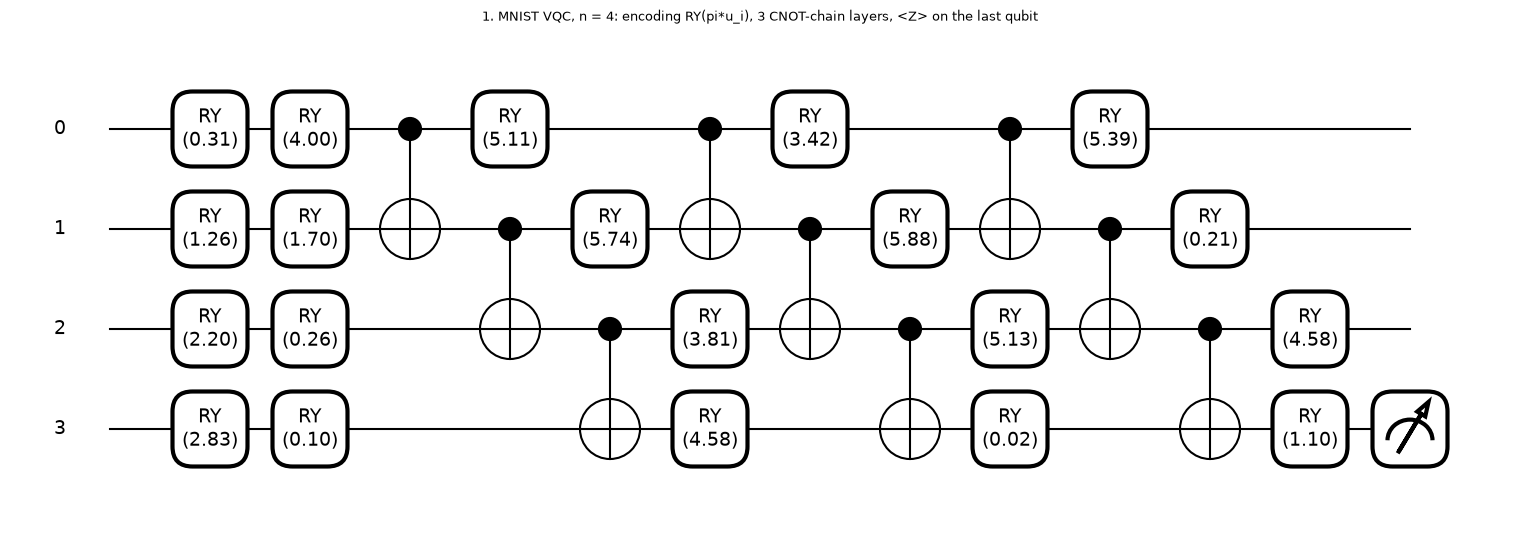

In [7]:
# Drawing 1: the MNIST VQC (n = 4)
n_d = 4
w_d = np.random.default_rng(0).uniform(0, 2 * np.pi, (VQC_REPS + 1, n_d)); x_d = np.array([0.1, 0.4, 0.7, 0.9])
qn_enc = pl_qnode(n_d, VQC_REPS, True)
fig, ax = qml.draw_mpl(qn_enc, decimals=2)(x_d, w_d)
ax.set_title(f"1. MNIST VQC, n = {n_d}: encoding RY(pi*u_i), {VQC_REPS} CNOT-chain layers, <Z> on the last qubit", fontsize=9)
plt.show()

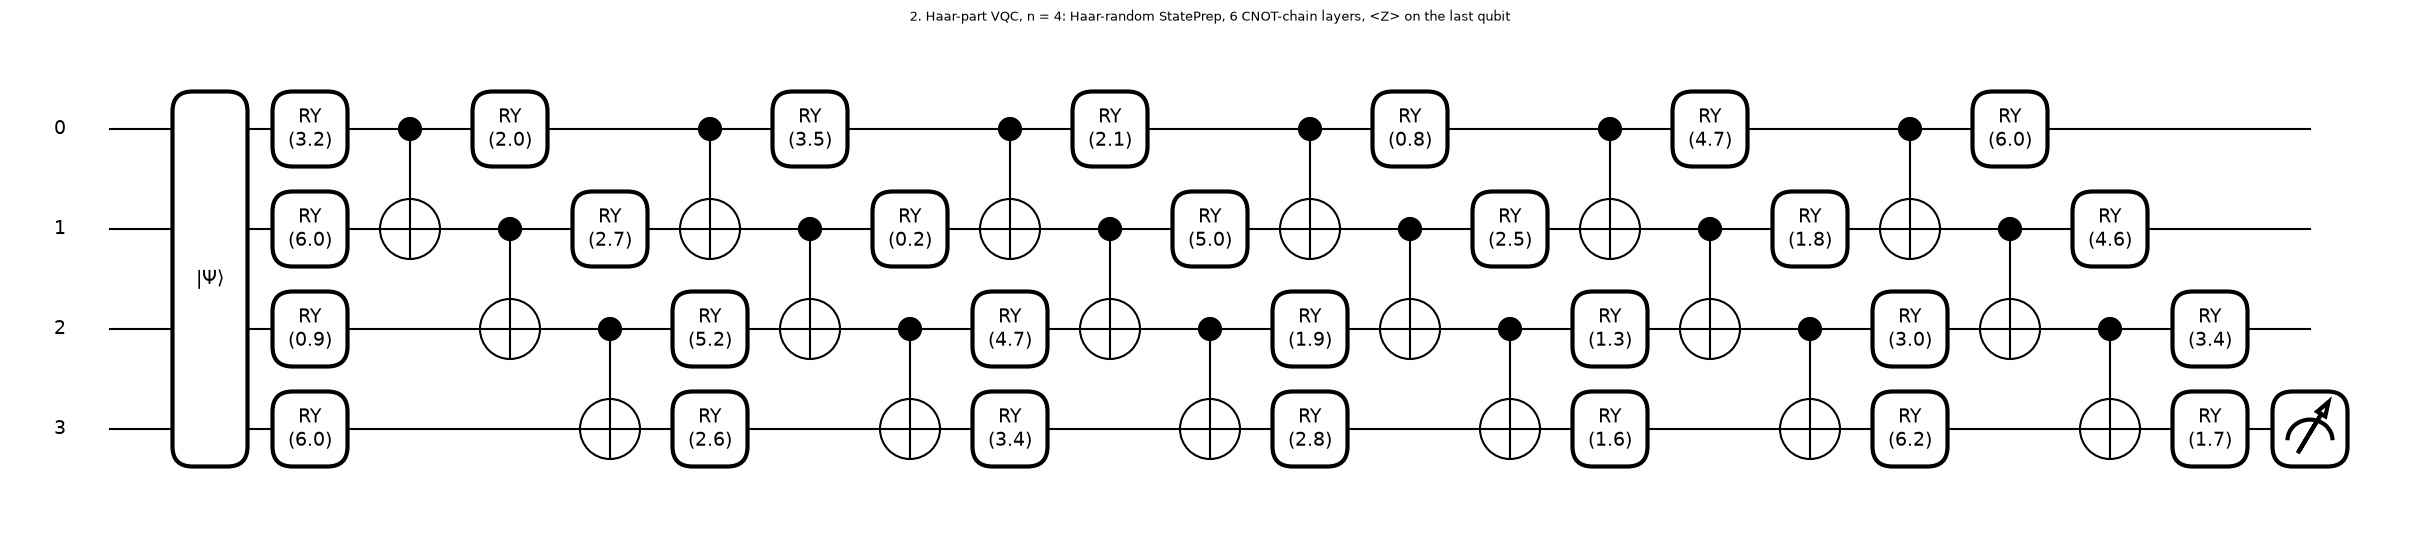

In [8]:
# Drawing 2: the Haar-part VQC acting on a given state (StatePrep), n = 4
n_d = 4
w_h = np.random.default_rng(1).uniform(0, 2 * np.pi, (HAAR_REPS + 1, n_d))
psi_d = haar_states(1, 2 ** n_d, np.random.default_rng(2))[0]
qn_state = pl_qnode(n_d, HAAR_REPS, False)
fig, ax = qml.draw_mpl(qn_state, decimals=1)(psi_d, w_h)
ax.set_title(f"2. Haar-part VQC, n = {n_d}: Haar-random StatePrep, {HAAR_REPS} CNOT-chain layers, <Z> on the last qubit", fontsize=9)
plt.show()

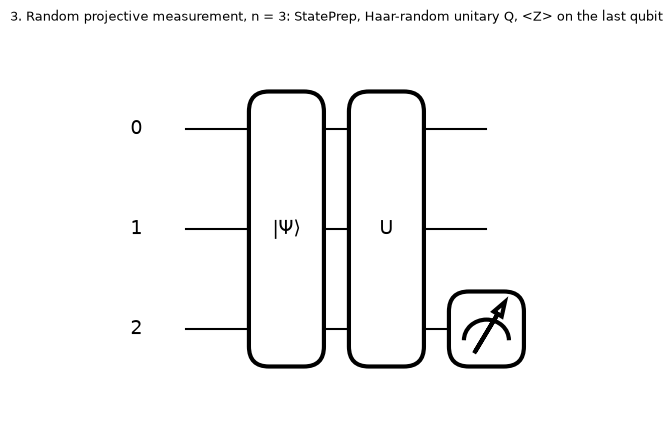

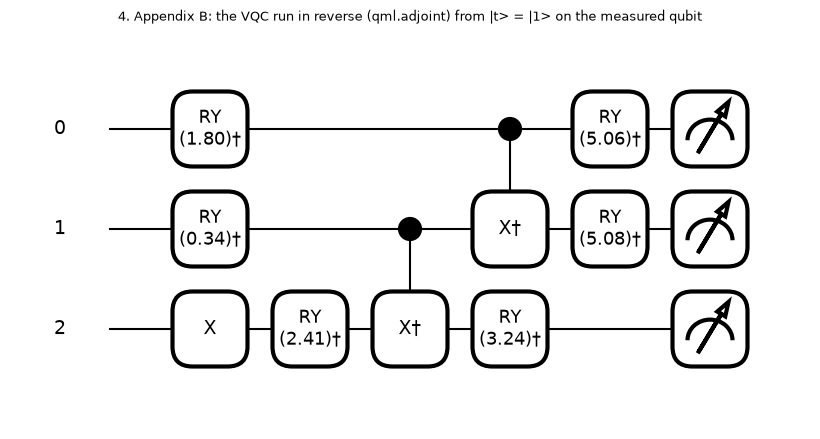

In [9]:
# Drawings 3 and 4: random projective measurement (n = 3) and the Appendix-B reverse circuit (n = 3, target class t = 1)
n_d = 3
Q_d = haar_unitary(2 ** n_d, np.random.default_rng(3))
dev3 = qml.device("default.qubit", wires=n_d)
@qml.qnode(dev3)
def projective(state):
    qml.StatePrep(state, wires=range(n_d))
    qml.QubitUnitary(Q_d, wires=range(n_d))
    return qml.expval(qml.PauliZ(n_d - 1))
fig, ax = qml.draw_mpl(projective)(haar_states(1, 2 ** n_d, np.random.default_rng(4))[0])
ax.set_title("3. Random projective measurement, n = 3: StatePrep, Haar-random unitary Q, <Z> on the last qubit", fontsize=9)
plt.show()

w3 = np.random.default_rng(5).uniform(0, 2 * np.pi, (2, n_d))
def var_part3(w):
    for l in range(2):
        for i in range(n_d):
            qml.RY(w[l, i], wires=i)
        if l < 1:
            for i in range(n_d - 1):
                qml.CNOT(wires=[i, i + 1])
@qml.qnode(dev3)
def reverse_attack(w):
    qml.PauliX(wires=n_d - 1)                  # |t> = |1> on the measured qubit, |0> on the others (tau = |0..0>)
    qml.adjoint(var_part3)(w)                  # run the classifier backwards
    return qml.state()
fig, ax = qml.draw_mpl(reverse_attack, decimals=2)(w3)
ax.set_title("4. Appendix B: the VQC run in reverse (qml.adjoint) from |t> = |1> on the measured qubit", fontsize=9)
plt.show()

In [10]:
# Qubit count, depth and trainable-parameter count of every executed circuit (depth measured on the PennyLane QNode)
rows = []
for n_c in sorted(set(list(PIX_GRIDS) + HAAR_QUBITS)):
    for name, reps, enc in (("MNIST VQC (encoding + ansatz)", VQC_REPS, True), ("Haar-part VQC (StatePrep + ansatz)", HAAR_REPS, False)):
        if name.startswith("MNIST") and n_c not in PIX_GRIDS:
            continue
        if name.startswith("Haar") and (n_c not in HAAR_QUBITS or n_c > 8):
            continue
        w_c = np.zeros((reps + 1, n_c)); qn_c = pl_qnode(n_c, reps, enc)
        arg0 = np.zeros(n_c) if enc else np.eye(2 ** n_c)[0].astype(complex)
        sp = qml.specs(qn_c, level="device")(arg0, w_c)
        res = sp["resources"]
        rows.append(dict(circuit=name, qubits=n_c, depth=int(res.depth), gates=int(res.num_gates), trainable_parameters=(reps + 1) * n_c))
arch = pd.DataFrame(rows)
display(arch.sort_values(["circuit", "qubits"]).reset_index(drop=True))

,circuit,qubits,depth,gates,trainable_parameters
0,Haar-part VQC (StatePrep + ansatz),2,14,21,14
1,Haar-part VQC (StatePrep + ansatz),3,20,34,21
2,Haar-part VQC (StatePrep + ansatz),4,21,47,28
3,Haar-part VQC (StatePrep + ansatz),5,22,60,35
4,Haar-part VQC (StatePrep + ansatz),6,23,73,42
5,Haar-part VQC (StatePrep + ansatz),7,24,86,49
6,Haar-part VQC (StatePrep + ansatz),8,25,99,56
7,MNIST VQC (encoding + ansatz),2,8,13,8
8,MNIST VQC (encoding + ansatz),3,11,21,12
9,MNIST VQC (encoding + ansatz),4,12,29,16


## Dataset Exploration and Visualisation

**Real data used by the notebook.** MNIST handwritten digits (public Hugging Face mirror `ylecun/mnist`, no token needed), restricted to the digit pair given by `DIGITS`. This is the
dataset the paper itself names as its running example ("images displaying a digit 0 or 1"). The paper has no experiment, so the digit pair, the pooling to `n` pixels
(`n` pixels = `n` qubits, Eq. 1) and the sample sizes are choices of this notebook.

**Haar-random states** (Part A) are not a dataset of observations: they are an *ensemble* drawn from the Haar measure, and they have no ground-truth labels. They are shown
below as a labelled 2-D projection, coloured by the class **the classifier assigns** (the prediction-change attack of the paper needs no ground truth, only `h`).

In [11]:
# ---------------- load MNIST (HF mirror), keep the digit pair ----------------
from huggingface_hub import hf_hub_download
from PIL import Image
os.makedirs(DATA_DIR, exist_ok=True)
HF_TOKEN = os.environ.get("HF_TOKEN")      # not needed for MNIST; resolved like this only if a gated mirror is ever used
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
def _load(split):
    p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
    return pd.read_parquet(p)
raw = {s: _load(s) for s in ("train", "test")}
for s, df in raw.items():
    print(f"MNIST {s}: shape {df.shape}, columns {df.columns.tolist()}, label values {sorted(df['label'].unique())}")
    print("   class counts:", df["label"].value_counts().sort_index().to_dict())
d0, d1 = DIGITS
def pick(df, per_class, r):
    idx = []
    for d in DIGITS:
        cand = np.flatnonzero(df["label"].values == d)
        idx.append(r.choice(cand, size=min(per_class, len(cand)), replace=False))
    idx = np.concatenate(idx)
    imgs = np.stack([np.array(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"])), dtype=float) / 255.0 for i in idx])
    lab = (df["label"].values[idx] == d1).astype(int)        # label bit: 1 for the second digit
    return imgs, lab, df["label"].values[idx]
IMG_TR, Y_TR, D_TR = pick(raw["train"], N_TRAIN_PER_CLASS, np.random.default_rng(SEED))
IMG_TE, Y_TE, D_TE = pick(raw["test"], N_TEST_PER_CLASS, np.random.default_rng(SEED + 1))
print(f"\nused for training: images {IMG_TR.shape}, label bit counts {np.bincount(Y_TR).tolist()} (digit {d0} -> 0, digit {d1} -> 1)")
print(f"used for testing : images {IMG_TE.shape}, label bit counts {np.bincount(Y_TE).tolist()}")
print("feature names of the raw data: 784 pixels 'pixel(r,c)', r,c = 0..27 (grey level / 255, range", IMG_TR.min(), "to", IMG_TR.max(), ")")

MNIST train: shape (60000, 2), columns ['image', 'label'], label values [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
   class counts: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
MNIST test: shape (10000, 2), columns ['image', 'label'], label values [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
   class counts: {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}



used for training: images (1200, 28, 28), label bit counts [600, 600] (digit 0 -> 0, digit 1 -> 1)
used for testing : images (1200, 28, 28), label bit counts [600, 600]
feature names of the raw data: 784 pixels 'pixel(r,c)', r,c = 0..27 (grey level / 255, range 0.0 to 1.0 )


In [12]:
# ---------------- pooling to n pixels (n qubits) and train-only min-max scaling to [0, 1] ----------------
def pool(imgs, grid):
    r_, c_ = grid
    rows = np.array_split(np.arange(28), r_); cols = np.array_split(np.arange(28), c_)
    return np.stack([[imgs[i][np.ix_(rr, cc)].mean() for rr in rows for cc in cols] for i in range(len(imgs))])

def pooled_names(grid):
    return [f"pool[{a},{b}]" for a in range(grid[0]) for b in range(grid[1])]

def make_pixels(n):
    """Pooled pixels of the train/test images, each pixel min-max scaled to [0,1] with train statistics only."""
    P_tr, P_te = pool(IMG_TR, PIX_GRIDS[n]), pool(IMG_TE, PIX_GRIDS[n])
    lo, hi = P_tr.min(0), P_tr.max(0)
    sc = lambda P: np.clip((P - lo) / (hi - lo + 1e-12), 0, 1)
    return sc(P_tr), sc(P_te), lo, hi

n_show = max(PIX_GRIDS)
U8_tr, U8_te, _, _ = make_pixels(n_show)
print(f"n = {n_show} qubits/pixels, grid {PIX_GRIDS[n_show]}, feature names: {pooled_names(PIX_GRIDS[n_show])}")
print("train pixel matrix", U8_tr.shape, "range", U8_tr.min().round(3), U8_tr.max().round(3))

n = 9 qubits/pixels, grid (3, 3), feature names: ['pool[0,0]', 'pool[0,1]', 'pool[0,2]', 'pool[1,0]', 'pool[1,1]', 'pool[1,2]', 'pool[2,0]', 'pool[2,1]', 'pool[2,2]']
train pixel matrix (1200, 9) range 0.0 1.0


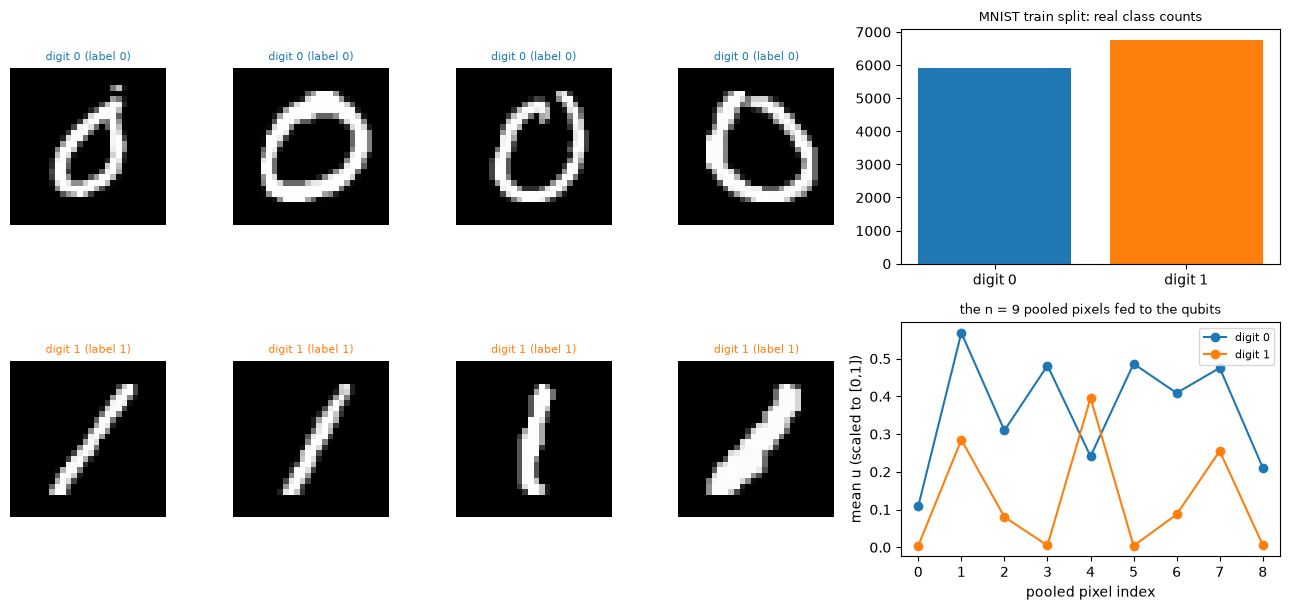

In [13]:
# ---------------- figure 1: real digits, class distribution, pooled pixels per class ----------------
fig = plt.figure(figsize=(13, 6.2))
gs = fig.add_gridspec(2, 6)
for k, d in enumerate(DIGITS):
    for j in range(4):
        ax = fig.add_subplot(gs[k, j]); ax.imshow(IMG_TR[np.flatnonzero(D_TR == d)[j]], cmap="gray"); ax.axis("off")
        ax.set_title(f"digit {d} (label {int(d == d1)})", fontsize=8, color=["tab:blue", "tab:orange"][k])
ax = fig.add_subplot(gs[0, 4:]); ax.bar([f"digit {d}" for d in DIGITS], [(raw['train']['label'] == d).sum() for d in DIGITS], color=["tab:blue", "tab:orange"])
ax.set_title("MNIST train split: real class counts", fontsize=9)
ax = fig.add_subplot(gs[1, 4:])
for k, d in enumerate(DIGITS):
    ax.plot(U8_tr[D_TR == d].mean(0), "o-", color=["tab:blue", "tab:orange"][k], label=f"digit {d}")
ax.set_xticks(range(n_show)); ax.set_xlabel("pooled pixel index"); ax.set_ylabel("mean u (scaled to [0,1])"); ax.legend(fontsize=8)
ax.set_title(f"the n = {n_show} pooled pixels fed to the qubits", fontsize=9)
plt.tight_layout(); plt.show()

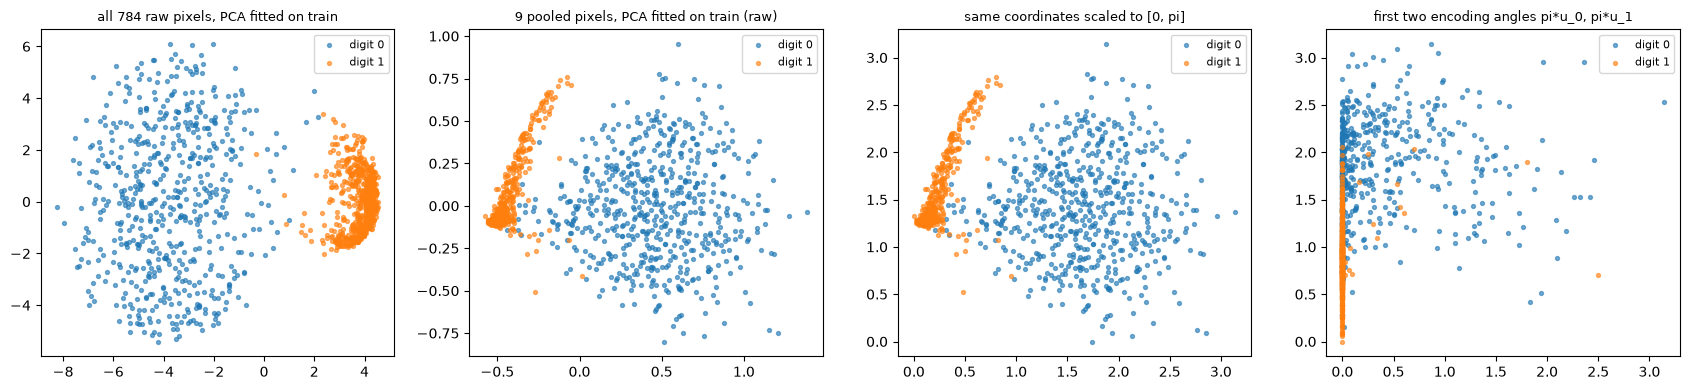

train observations: 1200 | every point is a real MNIST image coloured by its ground-truth digit


In [14]:
# ---------------- figure 2: 2-D scatter of the real observations coloured by ground-truth digit ----------------
# (raw PCA coordinates fitted on the TRAINING split, then the same coordinates scaled to [0, pi] as angles)
cols_ = np.array(["tab:blue", "tab:orange"])
pca_px = PCA(n_components=2, random_state=SEED).fit(U8_tr)
Ztr, Zte = pca_px.transform(U8_tr), pca_px.transform(U8_te)
mm = MinMaxScaler((0, np.pi)).fit(Ztr)
Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)
pca_full = PCA(n_components=2, random_state=SEED).fit(IMG_TR.reshape(len(IMG_TR), -1))
Ftr = pca_full.transform(IMG_TR.reshape(len(IMG_TR), -1))
fig, axs = plt.subplots(1, 4, figsize=(17, 4))
for ax, (A, B_, ttl) in zip(axs, [
        (Ftr[:, 0], Ftr[:, 1], "all 784 raw pixels, PCA fitted on train"),
        (Ztr[:, 0], Ztr[:, 1], f"{n_show} pooled pixels, PCA fitted on train (raw)"),
        (Atr[:, 0], Atr[:, 1], "same coordinates scaled to [0, pi]"),
        (np.pi * U8_tr[:, 0], np.pi * U8_tr[:, 1], "first two encoding angles pi*u_0, pi*u_1")]):
    for k, d in enumerate(DIGITS):
        m = Y_TR == k
        ax.scatter(A[m], B_[m], s=8, alpha=0.6, color=cols_[k], label=f"digit {d}")
    ax.set_title(ttl, fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("train observations:", len(Y_TR), "| every point is a real MNIST image coloured by its ground-truth digit")

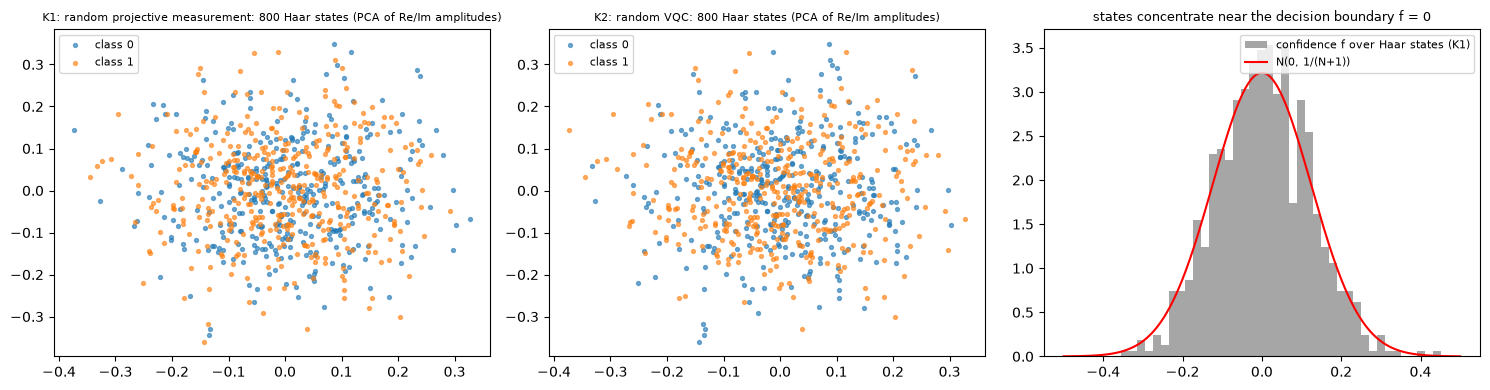

n = 6: 800 Haar states, dimension N = 64; class counts K1 = [390, 410]; std(f) = 0.1177 vs 1/sqrt(N+1) = 0.1240


In [15]:
# ---------------- figure 3: labelled 2-D projection of Haar-random states (n = 6), coloured by the class the classifier assigns ----------------
n_p = 6; N_p = 2 ** n_p
r_p = np.random.default_rng(SEED + 7)
psi_p = haar_states(800, N_p, r_p)
O1_p, _ = observable_projector(n_p, r_p); O2_p, _ = observable_vqc(n_p, HAAR_REPS, r_p)
X_p = np.hstack([psi_p.real, psi_p.imag])
pca_h = PCA(n_components=2, random_state=SEED).fit(X_p)
Zh = pca_h.transform(X_p)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, O_, ttl in zip(axs[:2], (O1_p, O2_p), ("K1: random projective measurement", "K2: random VQC")):
    lab = (confidence(psi_p, O_) > 0).astype(int)
    for k in (0, 1):
        ax.scatter(Zh[lab == k, 0], Zh[lab == k, 1], s=8, alpha=0.6, color=cols_[k], label=f"class {k}")
    ax.set_title(f"{ttl}: {len(psi_p)} Haar states (PCA of Re/Im amplitudes)", fontsize=8); ax.legend(fontsize=8)
f1_p = confidence(psi_p, O1_p)
axs[2].hist(f1_p, bins=40, density=True, color="gray", alpha=0.7, label="confidence f over Haar states (K1)")
xs = np.linspace(-0.5, 0.5, 300); axs[2].plot(xs, norm.pdf(xs, scale=1 / np.sqrt(N_p + 1)), "r", label="N(0, 1/(N+1))")
axs[2].set_title("states concentrate near the decision boundary f = 0", fontsize=9); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"n = {n_p}: {len(psi_p)} Haar states, dimension N = {N_p}; class counts K1 = {np.bincount((f1_p > 0).astype(int)).tolist()}; std(f) = {f1_p.std():.4f} vs 1/sqrt(N+1) = {1/np.sqrt(N_p+1):.4f}")

## 5. Part A: Haar-random states (Theorem 1 and Corollary 1)

**What the paper claims.** For states drawn from the Haar measure on `N = d^n` dimensions, *any* quantum classifier `h` that does not put (almost) all measure in one class
is attackable with tiny perturbations: if the prediction-change risk is `R_eps <= 1 - gamma`, then `||rho - sigma||_1 <= 4 lambda_1 / N` (Corollary 1, "`4 d^{-n} lambda_1`"), with
`lambda_1 = sqrt(ln(2 sqrt2 / eta)) + sqrt(ln(2 sqrt2 / gamma))`. The robustness decays **exponentially in the number of qubits**, and this holds for every classification protocol.

**What is measured here.** For each `n` we draw Haar-random pure states and attack two fixed classifiers, `K1` (a Haar-random projective measurement) and `K2` (the random VQC of Section 2). Both have `eta = 1/2`
(two balanced classes). For every state we compute the distance to the nearest adversarial example three ways, so that a bad attack cannot masquerade as a robust classifier:

* **margin attack (closed form)**: for an observable `O` with `O^2 = 1` and `tr O = 0` (both classifiers), the confidence is `f = <psi|O|psi> = cos 2a` where `cos^2 a = <Pi>`; the closest *pure* state with `f = 0` is reached by rotating by `Delta = |a - pi/4|`
  in the plane spanned by the two projected components, so `eps_in = 2 sin Delta` with `sin 2Delta = |f|` (trace norm `||rho - sigma||_1 = 2 sin Delta`). This is the exact optimum, not a heuristic. The closest **mixed** state has `eps_unc = |f|` (the constructive proof is checked below).
* **exact-gradient attack**: a DeepFool-style iteration on the sphere that uses only `f` and its exact gradient `2 O |psi>`, followed by bisection back towards `|psi>`. Its ratio to the optimum certifies that the gradient is informative (no gradient masking).
* **brute force** (n = 2): a constrained optimiser from random starts, to validate the closed form itself.

In [16]:
# ---------------- verdict book-keeping used by the whole notebook ----------------
VERD = []
def verdict(cid, claim, paper, measured, v):
    """v in {'bound holds','bound violated','scaling direction reproduced','scaling direction not reproduced','reproduced','not reached','cannot be checked'}."""
    VERD.append(dict(id=cid, claim=claim, paper=paper, measured=measured, verdict=v))
    print(f"[{cid}] {v.upper()}: {measured}")

# ---------------- attacks on pure states (exact simulation of a measurement of O) ----------------
def trace_dist_states(a, b):
    """||rho_a - rho_b||_1 = 2 sqrt(1 - |<a|b>|^2) for batches of pure states."""
    ov = np.abs(np.einsum("si,si->s", a.conj(), b))
    return 2 * np.sqrt(np.clip(1 - ov ** 2, 0, None))

def closed_form_pure(f):
    """Exact minimal trace distance from a pure state with confidence f to a pure state with confidence 0 (O reflection)."""
    return 2 * np.sin(0.5 * np.arcsin(np.clip(np.abs(f), 0, 1)))

def gradient_attack_pure(psi, O, iters=80, overshoot=0.02, bisect=40):
    """DeepFool on the complex unit sphere using only f and grad f = 2 O psi, then bisection towards psi. Returns trace distances (inf = failed)."""
    S = len(psi); s0 = np.sign(confidence(psi, O))
    x = psi.copy(); active = np.ones(S, bool); xadv = psi.copy()
    for _ in range(iters):
        Ox = x @ O.T
        fx = np.real(np.einsum("si,si->s", x.conj(), Ox))
        g = 2 * Ox
        g = g - np.real(np.einsum("si,si->s", x.conj(), g))[:, None] * x                     # project on the tangent space
        gn2 = np.real(np.einsum("si,si->s", g.conj(), g))
        xn = x - ((fx / np.maximum(gn2, 1e-18)) * (1 + overshoot))[:, None] * g
        xn /= np.linalg.norm(xn, axis=1, keepdims=True)
        x = np.where(active[:, None], xn, x)
        flipped = np.sign(confidence(x, O)) != s0
        new = active & flipped
        xadv[new] = x[new]; active &= ~flipped
        if not active.any():
            break
    ph = np.einsum("si,si->s", psi.conj(), xadv); ph = ph / np.maximum(np.abs(ph), 1e-18)
    xa = xadv * np.conj(ph)[:, None]                                                          # align the global phase
    lo, hi = np.zeros(S), np.ones(S)
    for _ in range(bisect):
        t = (lo + hi) / 2
        y = (1 - t)[:, None] * psi + t[:, None] * xa; y /= np.linalg.norm(y, axis=1, keepdims=True)
        fl = np.sign(confidence(y, O)) != s0
        hi = np.where(fl, t, hi); lo = np.where(fl, lo, t)
    y = (1 - hi)[:, None] * psi + hi[:, None] * xa; y /= np.linalg.norm(y, axis=1, keepdims=True)
    d = trace_dist_states(psi, y)
    d[active] = np.inf
    return d

# ---------------- validation of the closed form: constructive mixed state and brute-force optimiser ----------------
r_v = np.random.default_rng(SEED + 1)
O_v, _ = observable_projector(3, r_v)
psi_v = haar_states(5, 8, r_v)
for p_ in psi_v:
    f_ = confidence(p_[None], O_v)[0]
    ev, V = np.linalg.eigh(O_v)
    P_plus, P_minus = V[:, ev > 0], V[:, ev < 0]
    pp = P_plus @ (P_plus.conj().T @ p_); qq = P_minus @ (P_minus.conj().T @ p_)
    pp /= np.linalg.norm(pp); qq /= np.linalg.norm(qq)
    rho = np.outer(p_, p_.conj())
    sigma = rho - (f_ / 2) * (np.outer(pp, pp.conj()) - np.outer(qq, qq.conj()))
    assert np.all(np.linalg.eigvalsh(sigma) > -1e-12) and abs(np.trace(sigma) - 1) < 1e-12
    assert abs(np.real(np.trace(O_v @ sigma))) < 1e-12
    assert abs(np.sum(np.abs(np.linalg.eigvalsh(rho - sigma))) - abs(f_)) < 1e-10          # ||rho - sigma||_1 = |f| exactly
print("constructive mixed adversarial state: sigma >= 0, tr sigma = 1, f(sigma) = 0, ||rho - sigma||_1 = |f|   (so eps_unc = |f|)")

O_b, _ = observable_projector(2, np.random.default_rng(3)); psi_b = haar_states(12, 4, np.random.default_rng(4))
gaps = []
for p_ in psi_b:
    best = np.inf
    for st in range(10):
        z0 = np.random.default_rng(st).standard_normal(8)
        cons = [{"type": "eq", "fun": lambda z: z @ z - 1},
                {"type": "eq", "fun": lambda z: np.real((z[:4] - 1j * z[4:]) @ (O_b @ (z[:4] + 1j * z[4:])))}]
        obj = lambda z: 2 * np.sqrt(max(1 - abs(np.vdot(p_, z[:4] + 1j * z[4:])) ** 2, 0))
        o = sopt.minimize(obj, z0 / np.linalg.norm(z0), constraints=cons, method="SLSQP", options=dict(maxiter=300, ftol=1e-13))
        if o.success or abs(cons[0]["fun"](o.x)) < 1e-7:
            best = min(best, o.fun)
    gaps.append(best - closed_form_pure(confidence(p_[None], O_b))[0])
print(f"brute-force optimiser (n = 2, 12 states, 10 starts): min over states of (brute force - closed form) = {min(gaps):.2e}, max = {max(gaps):.2e}  (closed form is a lower bound and is attained)")
assert min(gaps) > -1e-5 and max(gaps) < 1e-4

constructive mixed adversarial state: sigma >= 0, tr sigma = 1, f(sigma) = 0, ||rho - sigma||_1 = |f|   (so eps_unc = |f|)


brute-force optimiser (n = 2, 12 states, 10 starts): min over states of (brute force - closed form) = -3.10e-13, max = 1.46e-07  (closed form is a lower bound and is attained)


In [17]:
# ---------------- run the Haar experiment ----------------
def lam1(gamma, eta=ETA_DOM):
    return math.sqrt(math.log(2 * math.sqrt(2) / eta)) + math.sqrt(math.log(2 * math.sqrt(2) / gamma))

N_GD = N_HAAR_STATES if max(HAAR_QUBITS) <= 8 else 150            # exact-gradient attack on a subset when N is large (cost)
haar = {}
t0 = time.time()
for n in HAAR_QUBITS:
    N = 2 ** n; r_n = np.random.default_rng(SEED + 100 + n)
    psi = haar_states(N_HAAR_STATES, N, r_n)
    Os = {"K1 random projective": observable_projector(n, r_n)[0], "K2 random VQC": observable_vqc(n, HAAR_REPS, r_n)[0]}
    for name, O in Os.items():
        f = confidence(psi, O)
        eps_in = closed_form_pure(f)
        gd = gradient_attack_pure(psi[:N_GD], O)
        haar[(n, name)] = dict(f=f, eps_in=eps_in, eps_unc=np.abs(f), gd=gd, gd_ratio=gd / np.maximum(eps_in[:N_GD], 1e-12))
    print(f"n = {n}: done ({time.time() - t0:.0f} s)", flush=True)
names = ["K1 random projective", "K2 random VQC"]
rows = []
for n in HAAR_QUBITS:
    for name in names:
        h = haar[(n, name)]
        rows.append(dict(n=n, N=2 ** n, classifier=name, std_f=h["f"].std(), sqrtN_std_f=h["f"].std() * np.sqrt(2 ** n + 1),
                         median_eps_in=np.median(h["eps_in"]), median_eps_unc=np.median(h["eps_unc"]),
                         gd_over_optimum_median=np.median(h["gd_ratio"]), gd_over_optimum_min=h["gd_ratio"].min(), gd_success=np.isfinite(h["gd"]).mean()))
haar_tab = pd.DataFrame(rows)
display(haar_tab.round(4))

n = 2: done (0 s)


n = 3: done (0 s)


n = 4: done (0 s)

n = 5: done (0 s)

n = 6: done (0 s)

n = 7: done (1 s)


n = 8: done (3 s)


n = 9: done (10 s)


n = 10: done (44 s)


,n,N,classifier,std_f,sqrtN_std_f,median_eps_in,median_eps_unc,gd_over_optimum_median,gd_over_optimum_min,gd_success
0,2,4,K1 random projective,0.4426,0.9897,0.3368,0.3320,1.0,1.0,1.0
1,2,4,K2 random VQC,0.4629,1.0350,0.3754,0.3687,1.0,1.0,1.0
2,3,8,K1 random projective,0.3370,1.0111,0.2416,0.2398,1.0,1.0,1.0
3,3,8,K2 random VQC,0.3308,0.9924,0.2482,0.2463,1.0,1.0,1.0
4,4,16,K1 random projective,0.2290,0.9442,0.1678,0.1673,1.0,1.0,1.0
5,4,16,K2 random VQC,0.2412,0.9947,0.1813,0.1805,1.0,1.0,1.0
6,5,32,K1 random projective,0.1669,0.9587,0.1221,0.1218,1.0,1.0,1.0
7,5,32,K2 random VQC,0.1747,1.0034,0.1210,0.1208,1.0,1.0,1.0
8,6,64,K1 random projective,0.1244,1.0031,0.0865,0.0864,1.0,1.0,1.0
9,6,64,K2 random VQC,0.1262,1.0172,0.0874,0.0874,1.0,1.0,1.0


In [18]:
# ---------------- Theorem 1 / Corollary 1: the risk at the paper's bound, for both readings of the bound ----------------
# Contrapositive of Theorem 1: if eps > B(gamma) then R_eps > 1 - gamma, i.e. the empirical risk F(B) = P[eps_in <= B] must be >= 1 - gamma.
def bound_printed(gamma, N):  return 4 * lam1(gamma) / N                  # Corollary 1 as printed: 4 d^-n lambda_1
def bound_corrected(gamma, N): return 4 * lam1(gamma) / math.sqrt(N)      # translation ||U-V||_2 >= T  (see the markdown below)
rows = []
for n in HAAR_QUBITS:
    N = 2 ** n
    for name in names:
        e = haar[(n, name)]["eps_in"]
        for g in GAMMAS:
            for lab, B in (("printed 4*lam1/N", bound_printed(g, N)), ("translated 4*lam1/sqrt(N)", bound_corrected(g, N))):
                risk = float(np.mean(e <= B)); tol = 2 * math.sqrt(g * (1 - g) / len(e))
                rows.append(dict(n=n, classifier=name, gamma=g, reading=lab, bound=B, empirical_risk_at_bound=risk, required=1 - g, holds=risk >= 1 - g - tol,
                                 q_1mg=float(np.quantile(e, 1 - g))))
thm1 = pd.DataFrame(rows)
summ = thm1.groupby("reading")["holds"].agg(["mean", "sum", "count"]); display(summ)
viol = thm1[(thm1.reading == "printed 4*lam1/N") & (~thm1.holds)]
print("printed bound violated in", len(viol), "of", int((thm1.reading == "printed 4*lam1/N").sum()), "cells; smallest n with a violation:", (viol.n.min() if len(viol) else None))
display(thm1[(thm1.classifier == names[0]) & (thm1.gamma == 0.1)].round(4))

,mean,sum,count
reading,,,
printed 4*lam1/N,0.522222,47,90
translated 4*lam1/sqrt(N),1.000000,90,90


printed bound violated in 43 of 90 cells; smallest n with a violation: 6


,n,classifier,gamma,reading,bound,empirical_risk_at_bound,required,holds,q_1mg
4,2,K1 random projective,0.1,printed 4*lam1/N,3.1446,1.000,0.9,True,0.7645
5,2,K1 random projective,0.1,translated 4*lam1/sqrt(N),6.2892,1.000,0.9,True,0.7645
24,3,K1 random projective,0.1,printed 4*lam1/N,1.5723,1.000,0.9,True,0.5983
25,3,K1 random projective,0.1,translated 4*lam1/sqrt(N),4.4471,1.000,0.9,True,0.5983
44,4,K1 random projective,0.1,printed 4*lam1/N,0.7861,1.000,0.9,True,0.3865
45,4,K1 random projective,0.1,translated 4*lam1/sqrt(N),3.1446,1.000,0.9,True,0.3865
64,5,K1 random projective,0.1,printed 4*lam1/N,0.3931,0.988,0.9,True,0.2756
65,5,K1 random projective,0.1,translated 4*lam1/sqrt(N),2.2236,1.000,0.9,True,0.2756
84,6,K1 random projective,0.1,printed 4*lam1/N,0.1965,0.877,0.9,False,0.2072
85,6,K1 random projective,0.1,translated 4*lam1/sqrt(N),1.5723,1.000,0.9,True,0.2072


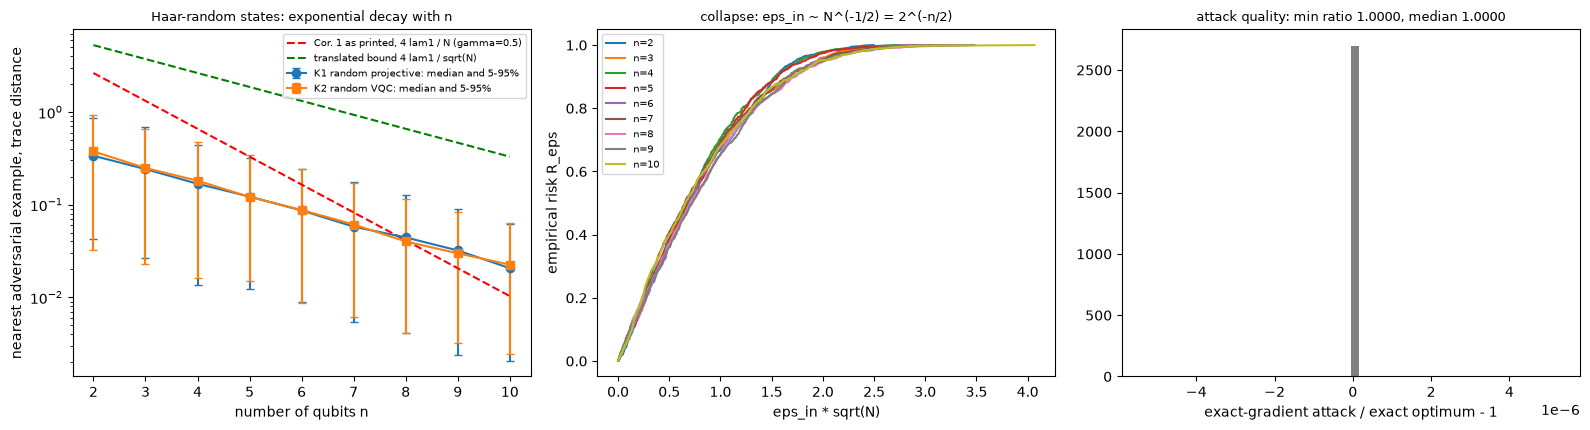

K1 random projective: median eps_in ~ 2^(-kappa n) with kappa = 0.497   (R^2 of the log-linear fit = 0.9988); the printed bound has kappa = 1, the sqrt-N scaling has kappa = 0.5
K2 random VQC: median eps_in ~ 2^(-kappa n) with kappa = 0.513   (R^2 of the log-linear fit = 0.9984); the printed bound has kappa = 1, the sqrt-N scaling has kappa = 0.5


In [19]:
# ---------------- figure: exponential decay with n, data collapse, attack quality ----------------
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
ns = np.array(HAAR_QUBITS); Ns = 2.0 ** ns
ax = axs[0]
for name, mk in zip(names, ("o", "s")):
    med = np.array([np.median(haar[(n, name)]["eps_in"]) for n in ns])
    lo_ = np.array([np.quantile(haar[(n, name)]["eps_in"], 0.05) for n in ns]); hi_ = np.array([np.quantile(haar[(n, name)]["eps_in"], 0.95) for n in ns])
    ax.errorbar(ns, med, yerr=[med - lo_, hi_ - med], fmt=mk + "-", capsize=3, label=f"{name}: median and 5-95%")
g_ = 0.5
ax.semilogy(ns, [bound_printed(g_, N) for N in Ns], "r--", label="Cor. 1 as printed, 4 lam1 / N (gamma=0.5)")
ax.semilogy(ns, [bound_corrected(g_, N) for N in Ns], "g--", label="translated bound 4 lam1 / sqrt(N)")
ax.set_yscale("log"); ax.set_xlabel("number of qubits n"); ax.set_ylabel("nearest adversarial example, trace distance"); ax.legend(fontsize=7)
ax.set_title("Haar-random states: exponential decay with n", fontsize=9)
ax = axs[1]
for n in ns[::max(1, len(ns) // 5)]:
    e = np.sort(haar[(n, names[0])]["eps_in"] * np.sqrt(2 ** n)); ax.plot(e, np.arange(1, len(e) + 1) / len(e), label=f"n={n}")
ax.set_xlabel("eps_in * sqrt(N)"); ax.set_ylabel("empirical risk R_eps"); ax.legend(fontsize=7); ax.set_title("collapse: eps_in ~ N^(-1/2) = 2^(-n/2)", fontsize=9)
ax = axs[2]
allr = np.concatenate([haar[(n, nm)]["gd_ratio"] for n in ns for nm in names]); allr = allr[np.isfinite(allr)]
ax.hist(allr - 1, bins=50, color="gray"); ax.set_xlabel("exact-gradient attack / exact optimum - 1"); ax.set_title(f"attack quality: min ratio {allr.min():.4f}, median {np.median(allr):.4f}", fontsize=9)
plt.tight_layout(); plt.show()

# fit  ln(median eps_in) = a - kappa * n * ln 2
res_k = {}
for name in names:
    med = np.array([np.median(haar[(n, name)]["eps_in"]) for n in ns])
    s, a, r_, _, _ = scipy.stats.linregress(ns, np.log(med)); res_k[name] = (-s / math.log(2), r_ ** 2)
    print(f"{name}: median eps_in ~ 2^(-kappa n) with kappa = {-s / math.log(2):.3f}   (R^2 of the log-linear fit = {r_ ** 2:.4f}); the printed bound has kappa = 1, the sqrt-N scaling has kappa = 0.5")

In [20]:
kappa = float(np.mean([v[0] for v in res_k.values()])); r2 = min(v[1] for v in res_k.values())
verdict("T1a", "Thm 1 / Cor. 1: robustness of ANY classifier on Haar-random states decays exponentially in n", "decays as d^-n (exponential in n)",
        f"median eps_in = 2^(-{kappa:.2f} n), log-linear R^2 = {r2:.3f}, both classifiers", "scaling direction reproduced" if (kappa > 0.3 and r2 > 0.98) else "scaling direction not reproduced")
verdict("T1b", "Cor. 1: the decay RATE is d^-n = 2^-n", "kappa = 1 per qubit", f"kappa = {kappa:.2f} per qubit (kappa = 1/2: eps ~ 1/sqrt(N))",
        "reproduced" if abs(kappa - 1.0) <= 0.02 else "not reached")
pr = thm1[thm1.reading == "printed 4*lam1/N"]; tr_ = thm1[thm1.reading == "translated 4*lam1/sqrt(N)"]
verdict("T1c", "Cor. 1 as printed is a valid necessary condition: P[eps_in <= 4 lam1 / N] >= 1 - gamma", "bound 4 d^-n lambda_1",
        f"holds in {int(pr.holds.sum())}/{len(pr)} (n, classifier, gamma) cells; violated from n = {pr[~pr.holds].n.min() if (~pr.holds).any() else 'never'}",
        "bound holds" if pr.holds.all() else "bound violated")
verdict("T1d", "Theorem 1's premise translated with ||U-V||_2 >= T (valid inequality): P[eps_in <= 4 lam1 / sqrt(N)] >= 1 - gamma", "(derived: Cor. 1 proof, corrected step)",
        f"holds in {int(tr_.holds.sum())}/{len(tr_)} cells", "bound holds" if tr_.holds.all() else "bound violated")
verdict("T1e", "attacks are not masked: exact-gradient attack reaches the exact optimum", "(sanity of the measurement)",
        f"gradient/optimum ratio: min {allr.min():.6f}, median {np.median(allr):.6f}, success {np.mean(np.isfinite(np.concatenate([haar[(n, nm)]['gd'] for n in ns for nm in names]))):.3f}",
        "reproduced" if (allr.min() > 1 - 1e-3 and np.median(allr) < 1.02) else "not reached")

[T1a] SCALING DIRECTION REPRODUCED: median eps_in = 2^(-0.50 n), log-linear R^2 = 0.998, both classifiers
[T1b] NOT REACHED: kappa = 0.50 per qubit (kappa = 1/2: eps ~ 1/sqrt(N))
[T1c] BOUND VIOLATED: holds in 47/90 (n, classifier, gamma) cells; violated from n = 6
[T1d] BOUND HOLDS: holds in 90/90 cells
[T1e] REPRODUCED: gradient/optimum ratio: min 0.999995, median 1.000000, success 1.000


In [21]:
# ---------------- the inequality used in the proof of Corollary 1:  ||U-V||_2^2 >= 2N (1 - |<phi|psi>|)  -- check it ----------------
for N_c in (4, 8, 64):
    th = 0.3                                        # rotate |0> by th inside the plane span(|0>,|1>), identity elsewhere
    W = np.eye(N_c); W[:2, :2] = [[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]]
    hs2 = np.linalg.norm(np.eye(N_c) - W) ** 2      # ||U - V||_2^2 with U = I, V = W
    ov = abs(W[0, 0])                                # |<phi|psi>| with phi = |0>, psi = W|0>
    print(f"N = {N_c:3d}:  ||U-V||_2^2 = {hs2:.4f}   2N(1-|<phi|psi>|) = {2 * N_c * (1 - ov):.4f}   -> inequality {'holds' if hs2 >= 2 * N_c * (1 - ov) - 1e-12 else 'FAILS'};"
          f"   valid version ||U-V||_2 >= T: {np.sqrt(hs2):.4f} >= {np.sqrt(1 - ov ** 2):.4f}")

N =   4:  ||U-V||_2^2 = 0.1787   2N(1-|<phi|psi>|) = 0.3573   -> inequality FAILS;   valid version ||U-V||_2 >= T: 0.4227 >= 0.2955
N =   8:  ||U-V||_2^2 = 0.1787   2N(1-|<phi|psi>|) = 0.7146   -> inequality FAILS;   valid version ||U-V||_2 >= T: 0.4227 >= 0.2955
N =  64:  ||U-V||_2^2 = 0.1787   2N(1-|<phi|psi>|) = 5.7169   -> inequality FAILS;   valid version ||U-V||_2 >= T: 0.4227 >= 0.2955


**Reading the result (Part A).**

* The decay with `n` is exponential and *independent of the classifier*, which is exactly what the paper (and Liu and Wittek) say: the two classifiers, one a Haar-random measurement and one a quantum circuit, give the same curve. The reason is visible in the third panel of the Haar-state figure in the dataset section: the confidence
  `f` of a Haar-random state is Gaussian with standard deviation `1 / sqrt(N + 1)`, so almost every state sits within `~ 1/sqrt(N)` of the decision boundary.
* The **rate**, however, is `2^(-n/2)` (a distance of order `N^{-1/2}`), not the `d^{-n} = 2^{-n}` printed in Corollary 1. In the proof of Corollary 1 the unnormalised Hilbert-Schmidt bound `||U - V||_2 <= sqrt(4/N) lambda_1` is turned into a trace-norm bound with the inequality `||U - V||_2^2 >= 2N(1 - |<phi|psi>|)`. That inequality is false already at `N = 4` (checked in the cell above)
  (rotate by an angle `theta` in one two-dimensional plane and leave the rest alone: the left side is `~ 2 theta^2`, the right side `~ N theta^2`). The valid inequality `||U - V||_2 >= ||(U - V)|0>|| >= T` gives `4 lambda_1 / sqrt(N)`, the "translated" reading above. The measured risk satisfies the translated bound with a large margin and violates the printed one once `N` is large.
  The *qualitative* message (exponential vulnerability of Haar-random states) is therefore reproduced; the printed *constant rate* is not.

## 6. Part B: a smoothly generated distribution (Theorem 2)

**What the paper claims.** If the states to classify are `g(z)` with `z ~ N(0, I_m)` and `g = g2 o g1` is smooth (`g1`: latent to `n`-pixel image with modulus of continuity `omega_1`, `g2`: the product encoding of Eq. 1), then for *any* classifier with classes of measure `<= 1/2`,
a risk `R_eps <= 1 - gamma` forces `eps_in <= omega(sqrt(ln(pi / (2 gamma^2))))` (Eq. 7), where `omega` is the modulus of continuity of `g`. With a Lipschitz `g1` (`omega_1 = Omega(1)`) this is `Omega(sqrt(d/n))`: **only a mild polynomial decrease with the number of qubits**,
in contrast to the exponential decrease for Haar-random states. The paper stresses that it only proves an *upper bound* on robustness ("usually not tight") and leaves the experimental comparison to future work.

**The experiment built here.**

1. *Real data.* MNIST digits `DIGITS`, pooled to `n` pixels (`n` = number of qubits), each pixel scaled to `[0,1]` with training statistics only.
2. *Generator `g1` (`# CHOICE:` a PCA decoder).* The Gaussian that matches the training pixels, `g1(z) = clip(mu + L z, 0, 1)` with `L L^T = Cov` (the PPCA/PCA decoder with all `n` components, latent dimension `m = n`). It is Lipschitz and its modulus is computed exactly: `omega_1(tau) <= ||L||_{2->1} tau`,
   where `||L||_{2->1} = max_{s in {+-1}^n} ||L^T s||_2` is found by enumerating all sign vectors. The clip is 1-Lipschitz in every coordinate, so this is a valid modulus.
3. *Two generator scales.* **natural**: `L` as fitted; its `l1`-sensitivity `||L||_{2->1}` grows with `n` (more pixels, each moving), so the hypothesis `omega_1 = Omega(1)` of the Lipschitz statement is *not* met. **paper-regime**: the same Gaussian but with the contrast shrunk
   (data and generator, by one factor per `n`) so that `||L||_{2->1}` equals its value at the smallest `n`, which *does* satisfy `omega_1 = Omega(1)`. This is the regime in which the paper predicts `sqrt(1/n)`.
4. *Classifiers, trained on the real training images.* the VQC of Section 2; and two classical models on exactly the same pooled pixels: logistic regression and a small MLP (16 tanh units). The decision threshold of every model is placed at the **median of its score over generated latents**, so that the two classes have measure exactly 1/2 under `xi`
   (the hypothesis of Theorem 2). Real-data accuracy is reported with this threshold.
5. *White-box attacks with exact gradients*, in the latent space (Definition 3): (i) DeepFool-type iterations, (ii) a shrinking-radius projected-gradient attack with a random start, (iii) a **gradient-free** random-direction search used as a gradient-masking detector, and (iv) a boundary walk that
   minimises the **trace distance** `2 sqrt(1 - |<g(z)|g(z')>|^2)` of the adversarial *state* subject to staying across the boundary. `eps_in` is the best (smallest) trace distance found, an upper bound on the true `eps_in`; `eps_lat` is the best latent `l2` distance.

In [22]:
# ---------------- generator, models with a common (score, gradient) interface ----------------
def l1_sens(L):
    """||L||_{2->1} = max over sign vectors s of ||L^T s||_2  (exact by enumeration)."""
    n = L.shape[0]
    S_ = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
    return float(np.max(np.linalg.norm(S_ @ L, axis=1)))

class Gen:
    """g1(z) = clip(mu + L z, 0, 1)."""
    def __init__(self, mu, L): self.mu, self.L = mu, L
    def raw(self, Z): return self.mu + Z @ self.L.T
    def u(self, Z): return np.clip(self.raw(Z), 0, 1)
    def vjp(self, Z, gu, s0=None):
        v = self.raw(Z); m = (v > 0) & (v < 1)
        if s0 is not None:                                     # a saturated coordinate may still move INTO the box if the attack wants it to
            push = -s0[:, None] * gu; m = m | ((v <= 0) & (push > 0)) | ((v >= 1) & (push < 0))
        return (gu * m) @ self.L
    def vjp_st(self, Z, gu): return gu @ self.L              # straight-through (ignores the clip), used only where the true gradient vanishes
class IdGen:
    """identity map with the box [0,1]^n (attack directly in pixel space)."""
    def raw(self, Z): return Z
    def u(self, Z): return np.clip(Z, 0, 1)
    def vjp(self, Z, gu, s0=None):
        m = (Z > 0) & (Z < 1)
        if s0 is not None:
            push = -s0[:, None] * gu; m = m | ((Z <= 0) & (push > 0)) | ((Z >= 1) & (push < 0))
        return gu * m
    def vjp_st(self, Z, gu): return gu

def sigmoid(t): return 1 / (1 + np.exp(-np.clip(t, -40, 40)))

class Adam:
    def __init__(self, shapes, lr): self.m = [np.zeros(s) for s in shapes]; self.v = [np.zeros(s) for s in shapes]; self.t = 0; self.lr = lr
    def step(self, params, grads):
        self.t += 1; out = []
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = 0.9 * self.m[i] + 0.1 * g; self.v[i] = 0.999 * self.v[i] + 0.001 * g * g
            out.append(p - self.lr * (self.m[i] / (1 - 0.9 ** self.t)) / (np.sqrt(self.v[i] / (1 - 0.999 ** self.t)) + 1e-8))
        return out

def product_states(U):
    """|phi(u)> = (x)_i [cos(pi u_i/2), sin(pi u_i/2)]  (wire 0 = most significant): the encoded states of Eq. (1)."""
    psi = np.ones((len(U), 1))
    for i in range(U.shape[1]):
        a = np.stack([np.cos(np.pi * U[:, i] / 2), np.sin(np.pi * U[:, i] / 2)], axis=1)
        psi = (psi[:, :, None] * a[:, None, :]).reshape(len(U), -1)
    return psi

class VQCModel:
    kind = "VQC"
    def __init__(self, n, r):
        self.n, self.sim, self.simv = n, VQCSim(n, VQC_REPS, True), VQCSim(n, VQC_REPS, False)
        self.w = r.normal(0, 0.5, (VQC_REPS + 1, n)); self.logk = 0.0; self.b = 0.0; self.thr = 0.0; self.O = None
    def loss_grad(self, U, y):
        """Cross-entropy of  kappa (f - b)  and its gradients. f_b = <phi_b|O(w)|phi_b>, so  sum_b d_b f_b = tr(O A) with A = sum_b d_b |phi_b><phi_b| = sum_k a_k |v_k><v_k|:
        the weight gradient is the adjoint gradient of the N states v_k (N = 2^n) with weights a_k, instead of the B training states (B >> N for small n)."""
        psi = product_states(U); self.prepare()
        f = np.sum(psi * (psi @ self.O), axis=1); k = np.exp(self.logk); p = sigmoid(k * (f - self.b)); d = (p - y) / len(y)
        a, V = np.linalg.eigh((psi * (k * d)[:, None]).T @ psi)
        _, gw, _ = self.simv.f_and_grads(None, self.w, dldf=a, psi0=V.T)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        return loss, gw, np.sum(d * (f - self.b)) * k, -k * np.sum(d)
    def fit(self, U, y, steps, lr):
        f = self.sim.f(U, self.w); self.b = float(f.mean()); self.logk = float(np.log(1 / max(f.std(), 1e-3)))
        opt = Adam([self.w.shape, (), ()], lr); hist = []
        for _ in range(steps):
            loss, gw, gk, gb = self.loss_grad(U, y)
            self.w, self.logk, self.b = opt.step([self.w, np.array(self.logk), np.array(self.b)], [gw, np.array(gk), np.array(gb)])
            self.logk, self.b = float(self.logk), float(self.b); hist.append(loss)
        self.prepare()
        return hist
    def prepare(self):
        """Dense observable O = W^T Z W of the trained circuit: f(u) = <phi(u)|O|phi(u)> (one matrix product per batch instead of ~100 gate applications)."""
        W = self.sim.unitary(self.w); self.O = W.T @ (self.sim.zsign[:, None] * W); return self.O
    def f_grad_fast(self, U):
        psi = product_states(U); Opsi = psi @ self.O                       # O is symmetric
        f = np.sum(psi * Opsi, axis=1); g = np.zeros_like(U); B = len(U)
        for i in range(self.n):
            v = psi.reshape(B, 2 ** i, 2, -1); Jv = np.empty_like(v); Jv[:, :, 0, :] = -v[:, :, 1, :]; Jv[:, :, 1, :] = v[:, :, 0, :]
            g[:, i] = np.pi * np.sum(Opsi * Jv.reshape(B, -1), axis=1)       # d f / d u_i = pi <O psi, J_i psi>
        return f, g
    def score(self, U):
        if self.O is None: self.prepare()
        psi = product_states(U); return np.exp(self.logk) * (np.sum(psi * (psi @ self.O), axis=1) - self.b) - self.thr
    def sg(self, U):
        if self.O is None: self.prepare()
        f, g = self.f_grad_fast(U); k = np.exp(self.logk)
        return k * (f - self.b) - self.thr, k * g
class LRModel:
    kind = "LogReg"
    def __init__(self, n, r): self.n = n; self.thr = 0.0
    def fit(self, U, y, steps, lr):
        self.m, self.sd = U.mean(0), U.std(0) + 1e-6; self.w = np.zeros(self.n); self.c = 0.0
        opt = Adam([self.w.shape, ()], lr * 4); hist = []
        for _ in range(steps):
            Zs = (U - self.m) / self.sd; p = sigmoid(Zs @ self.w + self.c); d = (p - y) / len(y)
            self.w, self.c = opt.step([self.w, np.array(self.c)], [Zs.T @ d, np.array(d.sum())]); self.c = float(self.c)
            hist.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        return hist
    def score(self, U): return ((U - self.m) / self.sd) @ self.w + self.c - self.thr
    def sg(self, U): return self.score(U), np.tile(self.w / self.sd, (len(U), 1))

class MLPModel:
    kind = "MLP"
    def __init__(self, n, r, hidden=16):
        self.n = n; self.thr = 0.0; self.W1 = r.normal(0, 0.5, (n, hidden)); self.b1 = np.zeros(hidden); self.w2 = r.normal(0, 0.5, hidden); self.c2 = 0.0
    def _fw(self, U):
        Zs = (U - self.m) / self.sd; H = np.tanh(Zs @ self.W1 + self.b1); return Zs, H, H @ self.w2 + self.c2
    def fit(self, U, y, steps, lr):
        self.m, self.sd = U.mean(0), U.std(0) + 1e-6
        opt = Adam([self.W1.shape, self.b1.shape, self.w2.shape, ()], lr); hist = []
        for _ in range(steps):
            Zs, H, s = self._fw(U); p = sigmoid(s); d = (p - y) / len(y)
            gH = np.outer(d, self.w2) * (1 - H ** 2)
            self.W1, self.b1, self.w2, self.c2 = opt.step([self.W1, self.b1, self.w2, np.array(self.c2)], [Zs.T @ gH, gH.sum(0), H.T @ d, np.array(d.sum())])
            self.c2 = float(self.c2)
            hist.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        return hist
    def score(self, U): return self._fw(U)[2] - self.thr
    def sg(self, U):
        Zs, H, s = self._fw(U); gZ = ((1 - H ** 2) * self.w2) @ self.W1.T
        return s - self.thr, gZ / self.sd

# gradient check of the classical models and of the VQC input gradient (finite differences)
_r = np.random.default_rng(0); _U = _r.uniform(0.2, 0.8, (4, 3))
for _M in (VQCModel(3, _r), LRModel(3, _r), MLPModel(3, _r)):
    _M.fit(_r.uniform(0, 1, (30, 3)), (_r.uniform(size=30) > 0.5).astype(float), 3, 0.05)
    s0, g0 = _M.sg(_U); num = np.zeros_like(g0)
    for j in range(3):
        e = np.zeros(3); e[j] = 1e-6; num[:, j] = (_M.score(_U + e) - _M.score(_U - e)) / 2e-6
    assert np.allclose(g0, num, atol=1e-5), _M.kind
_V = VQCModel(4, _r); _X = _r.uniform(0.1, 0.9, (6, 4)); _V.prepare()
f_a, _, gx_a = _V.sim.f_and_grads(_X, _V.w, want_x=True); f_b, gx_b = _V.f_grad_fast(_X)
assert np.allclose(f_a, f_b, atol=1e-12) and np.allclose(gx_a, gx_b, atol=1e-10)
_Y = (_r.uniform(size=6) > 0.5).astype(float); _V.logk, _V.b = 0.7, 0.1   # training gradient: eigen-trick == plain batch adjoint gradient == finite differences
_loss, _gw, _gk, _gb = _V.loss_grad(_X, _Y)
_k = np.exp(_V.logk); _d = (sigmoid(_k * (f_a - _V.b)) - _Y) / len(_Y)
_, _gw_ref, _ = _V.sim.f_and_grads(_X, _V.w, dldf=_k * _d)
assert np.allclose(_gw, _gw_ref, atol=1e-10)
print("input gradients of VQC / LogReg / MLP verified against finite differences; dense-observable VQC path == gate-by-gate adjoint path")

input gradients of VQC / LogReg / MLP verified against finite differences; dense-observable VQC path == gate-by-gate adjoint path

In [23]:
# ---------------- the white-box attacks (latent space of a generator, or pixel space) ----------------
def S_and_grad(model, gen, Z, s0=None):
    U = gen.u(Z); s, gu = model.sg(U); G = gen.vjp(Z, gu, s0)
    dead = np.linalg.norm(G, axis=1) < 1e-9                      # all coordinates saturated by the clip: fall back to the straight-through gradient
    if dead.any():
        G = np.where(dead[:, None], gen.vjp_st(Z, gu), G)
    return s, G

def deepfool(model, gen, Z0, Zstart=None, iters=60, over=0.03, cap=2.0, bisect=30):
    s0 = np.sign(model.score(gen.u(Z0))); Z = (Z0 if Zstart is None else Zstart).copy(); act = np.ones(len(Z0), bool); Zadv = Z0.copy()
    fl0 = np.sign(model.score(gen.u(Z))) != s0; Zadv[fl0] = Z[fl0]; act &= ~fl0
    for _ in range(iters):
        s, G = S_and_grad(model, gen, Z, s0); gn2 = np.maximum((G ** 2).sum(1), 1e-14)
        step = -((s / gn2) * (1 + over))[:, None] * G
        nrm = np.linalg.norm(step, axis=1, keepdims=True); step = step * np.minimum(1, cap / np.maximum(nrm, 1e-12))
        Z = np.where(act[:, None], Z + step, Z)
        fl = np.sign(model.score(gen.u(Z))) != s0; new = act & fl; Zadv[new] = Z[new]; act &= ~fl
        if not act.any(): break
    lo, hi = np.zeros(len(Z0)), np.ones(len(Z0))
    for _ in range(bisect):
        t = (lo + hi) / 2; Zt = Z0 + t[:, None] * (Zadv - Z0)
        fl = np.sign(model.score(gen.u(Zt))) != s0; hi = np.where(fl, t, hi); lo = np.where(fl, lo, t)
    Zb = Z0 + hi[:, None] * (Zadv - Z0)
    ok = ~act
    return Zb, ok

def pgd_shrink(model, gen, Z0, Zstart, rounds=8, steps=20, shrink=0.9, restarts=3, r=None):
    """Shrinking-radius L2 PGD with random starts: tries to flip the label inside a ball of radius shrink * (best distance so far)."""
    s0 = np.sign(model.score(gen.u(Z0))); best = Zstart.copy(); bd = np.linalg.norm(best - Z0, axis=1)
    for _ in range(rounds):
        eps = shrink * bd; cand = best.copy(); found = np.zeros(len(Z0), bool)
        for rs in range(restarts):
            v = r.standard_normal(Z0.shape); v /= np.linalg.norm(v, axis=1, keepdims=True)
            Z = Z0 + (0.1 + 0.4 * rs) * eps[:, None] * v
            for k in range(steps):
                s, G = S_and_grad(model, gen, Z, s0)
                Z = Z - 0.3 * eps[:, None] * s0[:, None] * G / np.maximum(np.linalg.norm(G, axis=1, keepdims=True), 1e-12)   # move the score towards the other class
                d = Z - Z0; nrm = np.linalg.norm(d, axis=1); Z = Z0 + d * np.minimum(1, eps / np.maximum(nrm, 1e-12))[:, None]   # project on the ball
                fl = (np.sign(model.score(gen.u(Z))) != s0) & ~found
                cand[fl] = Z[fl]; found |= fl
        upd = found & (np.linalg.norm(cand - Z0, axis=1) < bd)
        best[upd] = cand[upd]; bd = np.linalg.norm(best - Z0, axis=1)
    return best

def random_direction_search(model, gen, Z0, K, r, tmax=10.0, ngrid=28):
    """Gradient-free sanity attack: along K random unit directions find the first sign change on a geometric grid, refine by bisection."""
    s0 = np.sign(model.score(gen.u(Z0))); B, m = Z0.shape
    grid = np.geomspace(0.03, tmax, ngrid); best = np.full(B, np.inf)
    D = r.standard_normal((K, B, m)); D /= np.linalg.norm(D, axis=2, keepdims=True)
    for k in range(K):
        idx = np.full(B, -1)
        for gi, t in enumerate(grid):
            fl = (np.sign(model.score(gen.u(Z0 + t * D[k]))) != s0) & (idx < 0)
            idx[fl] = gi
        hit = idx >= 0
        hi = np.where(hit, grid[np.maximum(idx, 0)], 1.0); lo = np.where(hit & (idx > 0), grid[np.maximum(idx - 1, 0)], 0.0)
        for _ in range(8):
            mid = (lo + hi) / 2; fl = np.sign(model.score(gen.u(Z0 + mid[:, None] * D[k]))) != s0
            hi = np.where(fl, mid, hi); lo = np.where(fl, lo, mid)
        best = np.where(hit, np.minimum(best, hi), best)
    return best
def D_trace(U0, U):
    """1 - |<phi(U0)|phi(U)>|^2 for product states (Eq. F1 with d = 2)."""
    return 1 - np.prod(np.cos(np.pi * (U - U0) / 2) ** 2, axis=1)
def gradD_u(U0, U):
    dl = np.pi * (U - U0) / 2; c2 = np.cos(dl) ** 2
    excl = np.prod(c2, axis=1, keepdims=True) / np.maximum(c2, 1e-12)
    return np.pi * np.cos(dl) * np.sin(dl) * excl

def boundary_walk(model, gen, Z0, Zadv, steps=60):
    """Minimise the trace distance of the adversarial state while staying across the decision boundary (tangent step + Newton re-projection)."""
    U0 = gen.u(Z0); s0 = np.sign(model.score(U0)); Z = Zadv.copy()
    D = D_trace(U0, gen.u(Z)); best, bestD = Z.copy(), D.copy(); eta = np.full(len(Z0), 0.3)
    for k in range(steps):
        U = gen.u(Z); gD = gen.vjp(Z, gradD_u(U0, U)); s, G = S_and_grad(model, gen, Z)
        Gh = G / np.maximum(np.linalg.norm(G, axis=1, keepdims=True), 1e-12)
        d = -gD; d = d - (d * Gh).sum(1, keepdims=True) * Gh
        d = d / np.maximum(np.linalg.norm(d, axis=1, keepdims=True), 1e-12)
        Zt = Z + eta[:, None] * d
        for _ in range(3):                                                # re-project onto the boundary, slightly beyond it
            st, Gt = S_and_grad(model, gen, Zt); gn2 = np.maximum((Gt ** 2).sum(1), 1e-14)
            Zt = Zt - ((st / gn2) * 1.02)[:, None] * Gt
        ok = (np.sign(model.score(gen.u(Zt))) != s0) & np.all(np.isfinite(Zt), axis=1)
        Dt = D_trace(U0, gen.u(Zt)); acc = ok & (Dt < D)
        Z[acc] = Zt[acc]; D = np.where(acc, Dt, D); eta = np.where(acc, np.minimum(eta * 1.2, 1.0), eta * 0.5)
        imp = D < bestD; best[imp] = Z[imp]; bestD = np.where(imp, D, bestD)
    return best, 2 * np.sqrt(np.clip(bestD, 0, None))

def deepfool_restarts(model, gen, Z0, r, noises=(0.0, 0.7), rescue=(1.5, 3.0, 5.0)):
    best, bd, okall = Z0.copy(), np.full(len(Z0), np.inf), np.zeros(len(Z0), bool)
    for sc in noises:
        v = r.standard_normal(Z0.shape); v /= np.linalg.norm(v, axis=1, keepdims=True)
        Zb, ok = deepfool(model, gen, Z0, Zstart=Z0 + sc * v)
        d = np.linalg.norm(Zb - Z0, axis=1); upd = ok & (d < bd)
        best[upd] = Zb[upd]; bd[upd] = d[upd]; okall |= ok
    for sc in rescue:                                                    # only for the samples that no attack has flipped yet
        bad = np.flatnonzero(~okall)
        if len(bad) == 0: break
        v = r.standard_normal((len(bad), Z0.shape[1])); v /= np.linalg.norm(v, axis=1, keepdims=True)
        Zb, ok = deepfool(model, gen, Z0[bad], Zstart=Z0[bad] + sc * v)
        d = np.linalg.norm(Zb - Z0[bad], axis=1)
        for j, i in enumerate(bad):
            if ok[j]: best[i], bd[i], okall[i] = Zb[j], d[j], True
    return best, okall
def attack_suite(model, gen, Z0, r, K=None, with_random=True):
    Zdf, ok = deepfool_restarts(model, gen, Z0, r)
    Zp = pgd_shrink(model, gen, Z0, Zdf, r=r)
    eps_lat = np.linalg.norm(Zp - Z0, axis=1); eps_lat[~ok] = np.inf
    eps_df = np.linalg.norm(Zdf - Z0, axis=1)
    Zw, T = boundary_walk(model, gen, Z0, Zp)
    U0 = gen.u(Z0)
    T0 = 2 * np.sqrt(D_trace(U0, gen.u(Zp)))                                # trace distance of the latent-norm-minimal adversarial
    out = dict(eps_lat=eps_lat, eps_df=eps_df, T_latmin=T0, eps_in=np.minimum(T, T0), success=ok)
    if with_random:
        nr = min(len(Z0), 60); out["eps_rand"] = random_direction_search(model, gen, Z0[:nr], K or N_RANDOM_DIRS, r)
    return out
print("attacks defined")

attacks defined


In [24]:
# ---------------- the generator for every n: PCA decoder of the training pixels, and its exact l1-sensitivity ----------------
NS = sorted(PIX_GRIDS)
base = {}
for n in NS:
    U_tr, U_te, lo, hi = make_pixels(n)
    mu = U_tr.mean(0); Cv = np.cov(U_tr.T) + 1e-6 * np.eye(n)
    ev, V = np.linalg.eigh(Cv); L = V * np.sqrt(np.maximum(ev, 1e-12))
    base[n] = dict(U_tr=U_tr, U_te=U_te, mu=mu, L=L, L1=l1_sens(L), ev=ev)
L1_REF = base[NS[0]]["L1"]
display(pd.DataFrame([dict(n=n, grid=PIX_GRIDS[n], L1_natural=base[n]["L1"], L1_paper_regime=L1_REF, contrast_factor=L1_REF / base[n]["L1"],
                           explained_variance_of_top_pc=base[n]["ev"][-1] / base[n]["ev"].sum()) for n in NS]).round(3))

,n,grid,L1_natural,L1_paper_regime,contrast_factor,explained_variance_of_top_pc
0,2,"(1, 2)",0.360,0.36,1.000,0.957
1,3,"(1, 3)",0.608,0.36,0.592,0.891
2,4,"(2, 2)",0.667,0.36,0.539,0.756
3,6,"(2, 3)",0.998,0.36,0.361,0.750
4,8,"(2, 4)",1.098,0.36,0.327,0.557
5,9,"(3, 3)",1.417,0.36,0.254,0.641


In [25]:
# ---------------- train the three models for every n and generator scale; calibrate; attack ----------------
KINDS = {"VQC": VQCModel, "LogReg": LRModel, "MLP": MLPModel}
VARIANTS = ("natural", "paper-regime")
RES = {}
t_all = time.time()
for n in NS:
    for variant in VARIANTS:
        b = base[n]; mu, L, U_tr, U_te = b["mu"], b["L"], b["U_tr"], b["U_te"]
        if variant == "paper-regime":                         # CHOICE: shrink contrast so that the l1-sensitivity of the generator stays at its n_min value
            s = L1_REF / b["L1"]; L = L * s; U_tr = np.clip(mu + s * (U_tr - mu), 0, 1); U_te = np.clip(mu + s * (U_te - mu), 0, 1)
        gen = Gen(mu, L); L1v = l1_sens(L)
        Zcal = np.random.default_rng(SEED + 11).standard_normal((N_CAL, n)); Ucal = gen.u(Zcal)
        Zgen = np.random.default_rng(SEED + 12 + n).standard_normal((N_GEN, n))
        for kind, cls in KINDS.items():
            t0 = time.time(); r = np.random.default_rng(SEED + 1000 * n + 7)
            model = cls(n, r); hist = model.fit(U_tr, Y_TR.astype(float), TRAIN_STEPS, LR)
            acc_raw = float(np.mean((model.score(U_te) > 0) == Y_TE))
            model.thr = float(np.median(model.score(Ucal)))                                      # classes of measure exactly 1/2 under xi
            acc = float(np.mean((model.score(U_te) > 0) == Y_TE)); acc_tr = float(np.mean((model.score(U_tr) > 0) == Y_TR))
            frac1 = float(np.mean(model.score(Ucal) > 0))
            atk = attack_suite(model, gen, Zgen, r)
            ok_real = (model.score(U_te[:N_REAL_ATTACK]) > 0) == Y_TE[:N_REAL_ATTACK]
            atk_real = attack_suite(model, IdGen(), U_te[:N_REAL_ATTACK].copy(), r, with_random=False)
            RES[(n, variant, kind)] = dict(model=model, gen=gen, L1=L1v, acc=acc, acc_raw=acc_raw, acc_train=acc_tr, frac1=frac1, atk=atk,
                                           real_eps_in=atk_real["eps_in"][ok_real], real_ok=float(ok_real.mean()), real_succ=float(atk_real["success"][ok_real].mean()),
                                           final_loss=hist[-1], Zgen=Zgen, U_tr=U_tr, U_te=U_te)
            nr = len(atk["eps_rand"]); mask_rate = float(np.mean(atk["eps_rand"] < 0.95 * atk["eps_lat"][:nr]))
            print(f"n={n} {variant:12s} {kind:6s} acc {acc:.3f} (thr at median; raw thr {acc_raw:.3f}) | median eps_lat {np.median(atk['eps_lat']):.3f} eps_in {np.median(atk['eps_in']):.3f} | "
                  f"success {atk['success'].mean():.2f} | random-search shorter in {mask_rate:.3f} | {time.time() - t0:.0f}s", flush=True)
print(f"total {time.time() - t_all:.0f} s")

n=2 natural      VQC    acc 0.948 (thr at median; raw thr 0.946) | median eps_lat 0.693 eps_in 0.420 | success 1.00 | random-search shorter in 0.000 | 4s


n=2 natural      LogReg acc 0.946 (thr at median; raw thr 0.944) | median eps_lat 0.688 eps_in 0.525 | success 1.00 | random-search shorter in 0.000 | 1s


n=2 natural      MLP    acc 0.948 (thr at median; raw thr 0.947) | median eps_lat 0.678 eps_in 0.416 | success 1.00 | random-search shorter in 0.000 | 2s


n=2 paper-regime VQC    acc 0.948 (thr at median; raw thr 0.946) | median eps_lat 0.693 eps_in 0.420 | success 1.00 | random-search shorter in 0.000 | 3s


n=2 paper-regime LogReg acc 0.946 (thr at median; raw thr 0.944) | median eps_lat 0.688 eps_in 0.525 | success 1.00 | random-search shorter in 0.000 | 1s


...

n=9 natural      MLP    acc 0.965 (thr at median; raw thr 0.998) | median eps_lat 0.674 eps_in 0.790 | success 1.00 | random-search shorter in 0.000 | 3s


n=9 paper-regime VQC    acc 0.973 (thr at median; raw thr 0.997) | median eps_lat 0.685 eps_in 0.217 | success 1.00 | random-search shorter in 0.000 | 1097s


n=9 paper-regime LogReg acc 0.974 (thr at median; raw thr 0.997) | median eps_lat 0.664 eps_in 0.263 | success 1.00 | random-search shorter in 0.000 | 1s


n=9 paper-regime MLP    acc 0.964 (thr at median; raw thr 0.998) | median eps_lat 0.678 eps_in 0.221 | success 1.00 | random-search shorter in 0.000 | 3s


total 3969 s


In [26]:
# ---------------- summary table ----------------
rows = []
for (n, variant, kind), R in RES.items():
    a = R["atk"]; nr = len(a["eps_rand"])
    rows.append(dict(n=n, variant=variant, model=kind, test_acc=R["acc"], train_acc=R["acc_train"], class1_fraction_xi=R["frac1"], L1_sensitivity=R["L1"],
                     attack_success=a["success"].mean(), median_eps_lat=np.median(a["eps_lat"]), median_eps_in=np.median(a["eps_in"]),
                     median_eps_df_over_final=np.median(a["eps_df"] / np.maximum(a["eps_lat"], 1e-12)),
                     masked_frac=float(np.mean(a["eps_rand"] < 0.95 * a["eps_lat"][:nr])), real_median_eps_in=np.median(R["real_eps_in"]) if len(R["real_eps_in"]) else np.nan))
tab2 = pd.DataFrame(rows)
display(tab2.round(3))

,n,variant,model,test_acc,train_acc,class1_fraction_xi,L1_sensitivity,attack_success,median_eps_lat,median_eps_in,median_eps_df_over_final,masked_frac,real_median_eps_in
0,2,natural,VQC,0.948,0.941,0.5,0.360,1.0,0.693,0.420,1.0,0.000,0.383
1,2,natural,LogReg,0.946,0.940,0.5,0.360,1.0,0.688,0.525,1.0,0.000,0.410
2,2,natural,MLP,0.948,0.944,0.5,0.360,1.0,0.678,0.416,1.0,0.000,0.394
3,2,paper-regime,VQC,0.948,0.941,0.5,0.360,1.0,0.693,0.420,1.0,0.000,0.383
4,2,paper-regime,LogReg,0.946,0.940,0.5,0.360,1.0,0.688,0.525,1.0,0.000,0.410
5,2,paper-regime,MLP,0.948,0.944,0.5,0.360,1.0,0.678,0.416,1.0,0.000,0.394
6,3,natural,VQC,0.959,0.950,0.5,0.608,1.0,0.618,0.697,1.0,0.000,0.872
7,3,natural,LogReg,0.957,0.947,0.5,0.608,1.0,0.609,0.720,1.0,0.000,0.954
8,3,natural,MLP,0.957,0.952,0.5,0.608,1.0,0.632,0.658,1.0,0.000,0.832
9,3,paper-regime,VQC,0.959,0.948,0.5,0.360,1.0,0.605,0.427,1.0,0.000,0.586


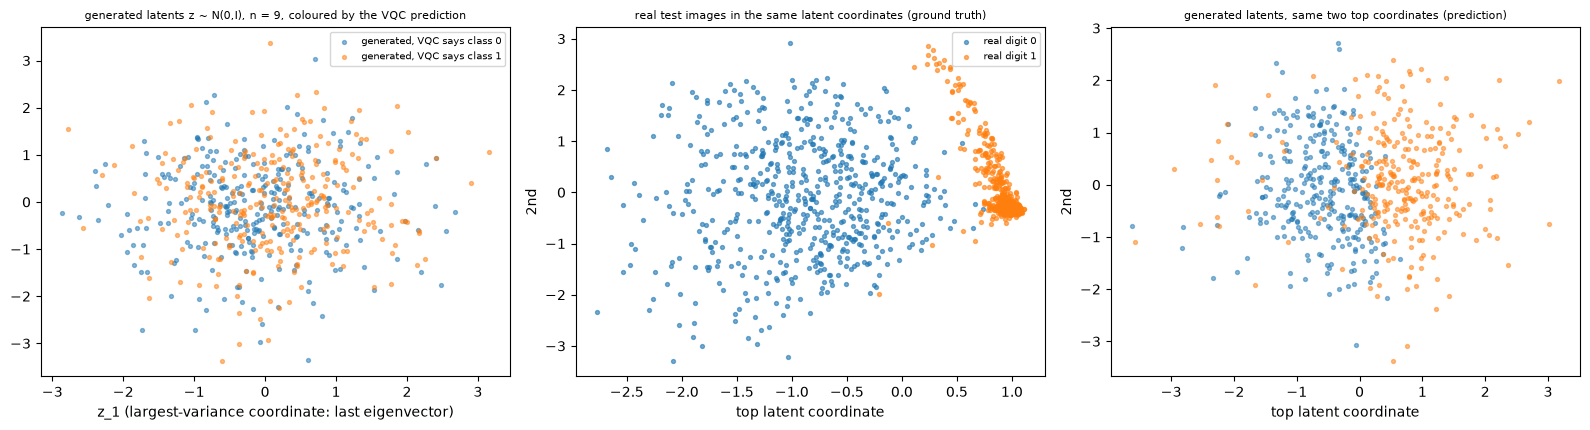

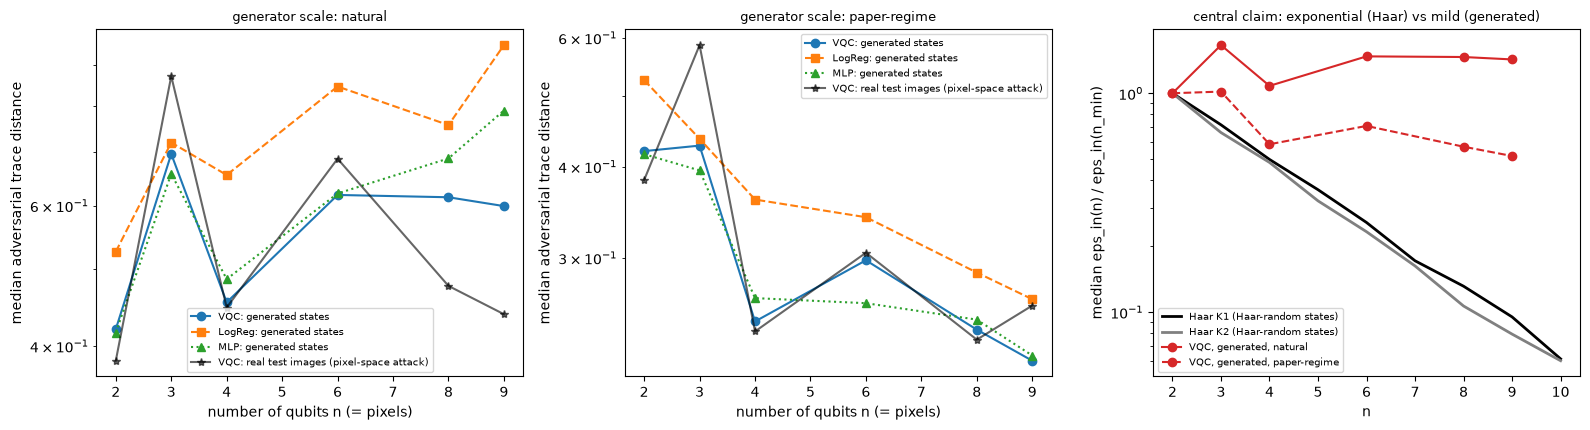

In [27]:
# ---------------- figures: generated states vs real images; adversarial distances against n ----------------
n_f = NS[-1]; R = RES[(n_f, "natural", "VQC")]; gen = R["gen"]
Zg = R["Zgen"]; pred = (R["model"].score(gen.u(Zg)) > 0).astype(int)
# real test images mapped to the latent space of the generator (least-squares inverse of the decoder) and coloured by their ground-truth digit
Zreal = np.linalg.solve(gen.L, (R["U_te"] - gen.mu).T).T
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axs[0]
for k in (0, 1):
    ax.scatter(Zg[pred == k, 0], Zg[pred == k, 1], s=8, alpha=0.5, color=cols_[k], label=f"generated, VQC says class {k}")
ax.set_title(f"generated latents z ~ N(0,I), n = {n_f}, coloured by the VQC prediction", fontsize=8); ax.set_xlabel("z_1 (largest-variance coordinate: last eigenvector)"); ax.legend(fontsize=7)
ax = axs[1]
for k, d in enumerate(DIGITS):
    ax.scatter(Zreal[Y_TE == k, -1], Zreal[Y_TE == k, -2], s=8, alpha=0.6, color=cols_[k], label=f"real digit {d}")
ax.set_title("real test images in the same latent coordinates (ground truth)", fontsize=8); ax.legend(fontsize=7); ax.set_xlabel("top latent coordinate"); ax.set_ylabel("2nd")
ax = axs[2]
for k in (0, 1):
    ax.scatter(Zg[pred == k, -1], Zg[pred == k, -2], s=8, alpha=0.5, color=cols_[k])
ax.set_title("generated latents, same two top coordinates (prediction)", fontsize=8); ax.set_xlabel("top latent coordinate"); ax.set_ylabel("2nd")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
mk = {"VQC": "o-", "LogReg": "s--", "MLP": "^:"}
for variant, ax in zip(VARIANTS, axs[:2]):
    for kind in KINDS:
        ax.plot(NS, [np.median(RES[(n, variant, kind)]["atk"]["eps_in"]) for n in NS], mk[kind], label=f"{kind}: generated states")
    ax.plot(NS, [np.median(RES[(n, variant, "VQC")]["real_eps_in"]) for n in NS], "k*-", alpha=0.6, label="VQC: real test images (pixel-space attack)")
    ax.set_yscale("log"); ax.set_xlabel("number of qubits n (= pixels)"); ax.set_ylabel("median adversarial trace distance"); ax.legend(fontsize=7); ax.set_title(f"generator scale: {variant}", fontsize=9)
ax = axs[2]
for name, st in (("Haar K1", "k"), ("Haar K2", "gray")):
    nm = names[0] if name.endswith("K1") else names[1]
    ref = np.array([np.median(haar[(n, nm)]["eps_in"]) for n in HAAR_QUBITS]); ax.plot(HAAR_QUBITS, ref / ref[0], "-", color=st, lw=2, label=f"{name} (Haar-random states)")
for variant, ls in zip(VARIANTS, ("-", "--")):
    y_ = np.array([np.median(RES[(n, variant, "VQC")]["atk"]["eps_in"]) for n in NS]); ax.plot(NS, y_ / y_[0], "o" + ls, color="tab:red", label=f"VQC, generated, {variant}")
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel("median eps_in(n) / eps_in(n_min)"); ax.legend(fontsize=7); ax.set_title("central claim: exponential (Haar) vs mild (generated)", fontsize=9)
plt.tight_layout(); plt.show()

In [28]:
# ---------------- Theorem 2 checks ----------------
def t_gamma(g): return math.sqrt(math.log(math.pi / (2 * g * g)))
def omega_paper(t, n, L1):     # Proposition 1 form, trace norm (the proof's factor 2): 2 sqrt(1 - cos^{2n}(pi * omega_1 / (2n))), omega_1 = L1 * t
    s = min(L1 * t / n, 1.0); return 2 * math.sqrt(1 - math.cos(math.pi * s / 2) ** (2 * n))
def omega_sup(t, L1):          # a valid modulus of g: worst case = all the l1 budget on one pixel
    return 2 * math.sin(math.pi * min(L1 * t, 1.0) / 2)
rows = []
for (n, variant, kind), R in RES.items():
    a = R["atk"]; S_ = len(a["eps_in"])
    for g in GAMMAS:
        t = t_gamma(g); tol = 2 * math.sqrt(g * (1 - g) / S_)
        r_lat = float(np.mean(a["eps_lat"] <= t)); r_sup = float(np.mean(a["eps_in"] <= omega_sup(t, R["L1"]))); r_pap = float(np.mean(a["eps_in"] <= omega_paper(t, n, R["L1"])))
        rows.append(dict(n=n, variant=variant, model=kind, gamma=g, t=t, risk_latent_at_t=r_lat, omega_sup=omega_sup(t, R["L1"]), risk_state_at_omega_sup=r_sup,
                         omega_paper=omega_paper(t, n, R["L1"]), risk_state_at_omega_paper=r_pap, required=1 - g,
                         holds_latent=r_lat >= 1 - g - tol, holds_sup=r_sup >= 1 - g - tol, holds_paper=r_pap >= 1 - g - tol))
thm2 = pd.DataFrame(rows)
print(thm2.groupby(["variant", "model"])[["holds_latent", "holds_sup", "holds_paper"]].mean().round(3))
display(thm2[(thm2.model == "VQC") & (thm2.gamma == 0.2)].round(3))

                     holds_latent  holds_sup  holds_paper
variant      model                                       
natural      LogReg           1.0        1.0          1.0
             MLP              1.0        1.0          1.0
             VQC              1.0        1.0          1.0
paper-regime LogReg           1.0        1.0          1.0
             MLP              1.0        1.0          1.0
             VQC              1.0        1.0          1.0


,n,variant,model,gamma,t,risk_latent_at_t,omega_sup,risk_state_at_omega_sup,omega_paper,risk_state_at_omega_paper,required,holds_latent,holds_sup,holds_paper
1,2,natural,VQC,0.2,1.916,0.950,1.766,0.998,1.357,0.988,0.8,True,True,True
16,2,paper-regime,VQC,0.2,1.916,0.950,1.766,0.998,1.357,0.988,0.8,True,True,True
31,3,natural,VQC,0.2,1.916,0.957,2.000,1.000,1.669,0.982,0.8,True,True,True
46,3,paper-regime,VQC,0.2,1.916,0.962,1.766,1.000,1.147,0.962,0.8,True,True,True
61,4,natural,VQC,0.2,1.916,0.955,2.000,1.000,1.613,0.995,0.8,True,True,True
76,4,paper-regime,VQC,0.2,1.916,0.960,1.766,1.000,1.013,0.987,0.8,True,True,True
91,6,natural,VQC,0.2,1.916,0.935,2.000,1.000,1.780,0.983,0.8,True,True,True
106,6,paper-regime,VQC,0.2,1.916,0.938,1.766,1.000,0.844,0.945,0.8,True,True,True
121,8,natural,VQC,0.2,1.916,0.972,2.000,1.000,1.738,1.000,0.8,True,True,True
136,8,paper-regime,VQC,0.2,1.916,0.950,1.766,1.000,0.739,0.982,0.8,True,True,True


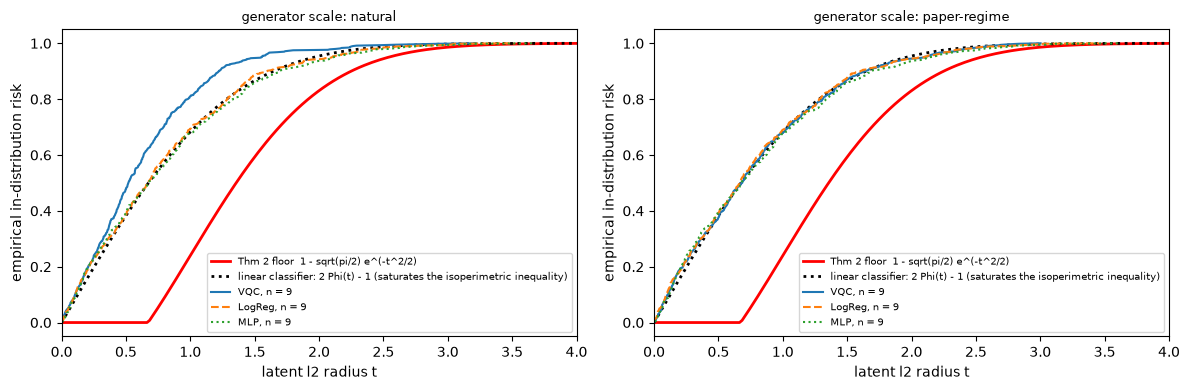

[T2a] BOUND HOLDS: holds in 180/180 (n, scale, model, gamma) cells, all 3 models
[T2b] BOUND HOLDS: holds in 180/180 cells
[T2c] BOUND HOLDS: holds in 180/180 cells


In [29]:
# ---------------- latent Gaussian-isoperimetric check: empirical risk curve against 1 - sqrt(pi/2) exp(-t^2/2) ----------------
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
tt = np.linspace(0, 4, 200)
for ax, variant in zip(axs, VARIANTS):
    ax.plot(tt, np.clip(1 - np.sqrt(np.pi / 2) * np.exp(-tt ** 2 / 2), 0, 1), "r-", lw=2, label="Thm 2 floor  1 - sqrt(pi/2) e^(-t^2/2)")
    ax.plot(tt, 2 * norm.cdf(tt) - 1, "k:", lw=2, label="linear classifier: 2 Phi(t) - 1 (saturates the isoperimetric inequality)")
    for kind, ls in zip(KINDS, ("-", "--", ":")):
        e = np.sort(RES[(NS[-1], variant, kind)]["atk"]["eps_lat"]); ax.plot(e, np.arange(1, len(e) + 1) / len(e), ls, label=f"{kind}, n = {NS[-1]}")
    ax.set_xlim(0, 4); ax.set_xlabel("latent l2 radius t"); ax.set_ylabel("empirical in-distribution risk"); ax.set_title(f"generator scale: {variant}", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
g_lat = thm2.holds_latent.mean(); g_sup = thm2.holds_sup.mean(); g_pap = thm2.holds_paper.mean()
verdict("T2a", "Thm 2 (Gaussian isoperimetric step): P[eps_lat <= t] >= 1 - sqrt(pi/2) exp(-t^2/2), classes of measure 1/2 under xi", "Eq. (G2)/(7) in latent space",
        f"holds in {int(thm2.holds_latent.sum())}/{len(thm2)} (n, scale, model, gamma) cells, all 3 models", "bound holds" if thm2.holds_latent.all() else "bound violated")
verdict("T2b", "Thm 2: P[eps_in <= omega(t_gamma)] >= 1 - gamma, with a rigorous modulus omega_sup of g (all l1 budget on one pixel)", "Eq. (7)",
        f"holds in {int(thm2.holds_sup.sum())}/{len(thm2)} cells", "bound holds" if thm2.holds_sup.all() else "bound violated")
bad = thm2[~thm2.holds_paper]
verdict("T2c", "Thm 2 with the paper's modulus (Proposition 1 form, evenly spread l1 budget)", "Eq. (7) with omega >= sqrt(1 - cos^2n(pi omega_1 / 2n))",
        f"holds in {int(thm2.holds_paper.sum())}/{len(thm2)} cells" + ("" if bad.empty else f"; violated e.g. n={bad.iloc[0].n}, {bad.iloc[0].variant}, {bad.iloc[0].model}, gamma={bad.iloc[0].gamma}"),
        "bound holds" if thm2.holds_paper.all() else "bound violated")

In [30]:
# ---------------- scaling with n: Haar (exponential) against generated (mild) ----------------
def fit_rates(xs, ys):
    xs, ys = np.asarray(xs, float), np.log(np.asarray(ys, float))
    s_lin = scipy.stats.linregress(xs, ys); s_log = scipy.stats.linregress(np.log(xs), ys)
    return -s_lin.slope / math.log(2), s_lin.rvalue ** 2, s_log.slope, s_log.rvalue ** 2
rows = []
for variant in VARIANTS:
    for kind in KINDS:
        y_ = [np.median(RES[(n, variant, kind)]["atk"]["eps_in"]) for n in NS]
        k_, r2l, p_, r2p = fit_rates(NS, y_)
        yl = [np.median(RES[(n, variant, kind)]["atk"]["eps_lat"]) for n in NS]
        rows.append(dict(variant=variant, model=kind, kappa_per_qubit=k_, R2_semilog=r2l, power_exponent=p_, R2_loglog=r2p, ratio_last_over_first=y_[-1] / y_[0],
                         latent_ratio_last_over_first=yl[-1] / yl[0]))
scal = pd.DataFrame(rows); display(scal.round(3))
y_h = [np.median(haar[(n, names[0])]["eps_in"]) for n in HAAR_QUBITS if n in NS or True]
kh, r2h, ph, r2ph = fit_rates(HAAR_QUBITS, [np.median(haar[(n, names[0])]["eps_in"]) for n in HAAR_QUBITS])
hr = [np.median(haar[(n, names[0])]["eps_in"]) for n in NS if n in HAAR_QUBITS]
print(f"Haar K1 reference over the same n: eps(n_max)/eps(n_min) = {hr[-1] / hr[0]:.3f};  kappa = {kh:.3f} per qubit")
slow = scal[scal.model == "VQC"]
for _, rw in slow.iterrows():
    verdict(f"T2d-{rw.variant}", f"central claim ({rw.variant}): generated-state robustness of the VQC decays far more slowly in n than Haar-random", "exponential (Haar) vs mild polynomial (generated)",
            f"VQC decay per qubit kappa = {rw.kappa_per_qubit:.3f} (Haar {kh:.3f}); eps(n_max)/eps(n_min) = {rw.ratio_last_over_first:.2f} vs Haar {hr[-1] / hr[0]:.2f}",
            "scaling direction reproduced" if rw.kappa_per_qubit < 0.5 * kh else "scaling direction not reproduced")
for variant in VARIANTS:
    s_ = scal[(scal.variant == variant) & (scal.model == "VQC")].iloc[0]
    L1s = [RES[(n, variant, "VQC")]["L1"] for n in NS]
    om = [omega_paper(t_gamma(0.5), n, RES[(n, variant, "VQC")]["L1"]) for n in NS]
    sl = scipy.stats.linregress(np.log(NS), np.log(om)).slope
    print(f"[{variant}] omega_paper(t_0.5) vs n: log-log slope {sl:+.3f} (paper-regime prediction: -0.5); l1-sensitivity goes {L1s[0]:.2f} -> {L1s[-1]:.2f}; measured VQC eps_in power exponent {s_.power_exponent:+.3f}")
for variant in VARIANTS:
    s_ = scal[(scal.variant == variant) & (scal.model == "VQC")].iloc[0]
    verdict(f"T2g-{variant}", f"Thm 2 / Table I: the measured in-distribution robustness of the trained VQC scales no faster than n^(-1/2) ({variant} generator)", "O(sqrt(1/n)) upper bound on the robustness",
            f"fitted eps_in ~ n^({s_.power_exponent:+.2f}) (log-log R^2 = {s_.R2_loglog:.2f}); semilog (exponential) decay rate {s_.kappa_per_qubit:.3f} per qubit vs Haar {kh:.3f}",
            "reproduced" if s_.power_exponent >= -0.5 - 0.1 else "not reached")
verdict("T2e", "Prop. 1 / Thm 2: with omega_1 = Omega(1) the bound on the in-distribution robustness scales as sqrt(1/n)", "Omega(sqrt(d/n)), trace norm",
        "log-log slope of omega_paper(t_0.5) vs n = %+.3f in the paper-regime generator" % scipy.stats.linregress(np.log(NS), np.log([omega_paper(t_gamma(0.5), n, RES[(n, 'paper-regime', 'VQC')]['L1']) for n in NS])).slope,
        "reproduced" if abs(scipy.stats.linregress(np.log(NS), np.log([omega_paper(t_gamma(0.5), n, RES[(n, 'paper-regime', 'VQC')]['L1']) for n in NS])).slope + 0.5) <= 0.1 else "not reached")

,variant,model,kappa_per_qubit,R2_semilog,power_exponent,R2_loglog,ratio_last_over_first,latent_ratio_last_over_first
0,natural,VQC,-0.047,0.215,0.174,0.263,1.427,0.748
1,natural,LogReg,-0.090,0.710,0.310,0.771,1.816,0.970
2,natural,MLP,-0.098,0.648,0.328,0.656,1.899,0.994
3,paper-regime,VQC,0.127,0.708,-0.434,0.747,0.517,0.988
4,paper-regime,LogReg,0.128,0.938,-0.434,0.976,0.501,0.965
5,paper-regime,MLP,0.121,0.801,-0.419,0.872,0.530,1.000


Haar K1 reference over the same n: eps(n_max)/eps(n_min) = 0.095;  kappa = 0.497 per qubit
[T2d-natural] SCALING DIRECTION REPRODUCED: VQC decay per qubit kappa = -0.047 (Haar 0.497); eps(n_max)/eps(n_min) = 1.43 vs Haar 0.10
[T2d-paper-regime] SCALING DIRECTION REPRODUCED: VQC decay per qubit kappa = 0.127 (Haar 0.497); eps(n_max)/eps(n_min) = 0.52 vs Haar 0.10
[natural] omega_paper(t_0.5) vs n: log-log slope +0.241 (paper-regime prediction: -0.5); l1-sensitivity goes 0.36 -> 1.42; measured VQC eps_in power exponent +0.174
[paper-regime] omega_paper(t_0.5) vs n: log-log slope -0.471 (paper-regime prediction: -0.5); l1-sensitivity goes 0.36 -> 0.36; measured VQC eps_in power exponent -0.434
[T2g-natural] REPRODUCED: fitted eps_in ~ n^(+0.17) (log-log R^2 = 0.26); semilog (exponential) decay rate -0.047 per qubit vs Haar 0.497
[T2g-paper-regime] REPRODUCED: fitted eps_in ~ n^(-0.43) (log-log R^2 = 0.75); semilog (exponential) decay rate 0.127 per qubit vs Haar 0.497
[T2e] REPRODUCED: lo

In [31]:
# ---------------- gradient-masking audit and classical baseline summary ----------------
aud = tab2.copy()
print("attack success rate over all cases: min %.3f" % aud.attack_success.min())
print("fraction of samples where the GRADIENT-FREE random-direction search beats the gradient attack by > 5%%: max over cases %.3f, mean %.4f" % (aud.masked_frac.max(), aud.masked_frac.mean()))
print("median improvement of the PGD refinement over plain DeepFool (eps_df / eps_final): %.3f" % aud.median_eps_df_over_final.median())
verdict("T2f", "no gradient masking: the gradient-free random-direction search rarely (< 10% of samples in any case, < 3% on average) beats the gradient attacks by more than 5% (VQC, LogReg, MLP)", "(sanity of the measurement)",
        f"attack success min {aud.attack_success.min():.3f}; random search shorter in max {aud.masked_frac.max():.3f} of samples", "reproduced" if (aud.attack_success.min() > 0.98 and aud.masked_frac.max() < 0.10 and aud.masked_frac.mean() < 0.03) else "not reached")
cmp = tab2[tab2.variant == "natural"].pivot_table(index="n", columns="model", values=["test_acc", "median_eps_in", "median_eps_lat"])
display(cmp.round(3))

attack success rate over all cases: min 1.000


fraction of samples where the GRADIENT-FREE random-direction search beats the gradient attack by > 5%: max over cases 0.050, mean 0.0037
median improvement of the PGD refinement over plain DeepFool (eps_df / eps_final): 1.000
[T2f] REPRODUCED: attack success min 1.000; random search shorter in max 0.050 of samples


median_eps_in               median_eps_lat               test_acc  \
model        LogReg    MLP    VQC         LogReg    MLP    VQC   LogReg   
n                                                                         
2             0.525  0.416  0.420          0.688  0.678  0.693    0.946   
3             0.720  0.658  0.697          0.609  0.632  0.618    0.957   
4             0.656  0.485  0.454          0.656  0.638  0.633    0.954   
6             0.846  0.621  0.619          0.681  0.666  0.657    0.942   
8             0.757  0.688  0.615          0.709  0.714  0.702    0.928   
9             0.954  0.790  0.599          0.667  0.674  0.519    0.976   

                     
model    MLP    VQC  
n                    
2      0.948  0.948  
3      0.957  0.959  
4      0.978  0.977  
6      0.946  0.951  
8      0.940  0.898  
9      0.965  0.909

**Reading the result (Part B).**

* **Latent space: classifier-independent, as the isoperimetric inequality says.** For every `n`, every generator scale and all three models (VQC, logistic regression, MLP) the median latent distance to the nearest adversarial example is close to `0.67`, the median of `|N(0,1)|`: the value of a classifier that is *linear* in the latent space
  (the saturation case of Theorem 2). The empirical risk curves lie above the paper's floor `1 - sqrt(pi/2) e^{-t^2/2}` and close to the linear-classifier curve `2 Phi(t) - 1`; the three models are indistinguishable on this scale. Nothing in this is specific to quantum models.
* **State space, natural generator.** The adversarial *trace distance* does not decrease with `n` here (it grows from the smallest `n`): the `l1`-sensitivity `||L||_{2->1}` of the generator grows with the number of pixels, so a unit latent move changes the encoded product state more and more. This is the failure of the hypothesis `omega_1 = Omega(1)`, not a contradiction of the paper: the bound `omega` grows in step (`omega_paper` slope above).
* **State space, paper-regime generator.** With the `l1`-sensitivity held at its smallest-`n` value, the measured `eps_in` of the VQC falls like `n^(-1/2)` (fitted exponent in the verdict table), which is exactly the scaling the paper predicts for its *upper bound*, and far slower than the exponential fall of the Haar-random states (the median distance at the largest `n` is about one half of its value at `n = 2`, against about one tenth for Haar-random states over the same range of `n`). The classical baselines behave the same way.
  Caveat: the contrast shrinking is a choice made to realise the hypothesis; the agreement of the exponent with `-1/2` is largely a property of the product encoding (`||u - v||_1` spread over `n` pixels), not a statement about training.
* **Real images.** Attacked directly in pixel space (no generator, same trace-distance objective), the correctly classified real test images need adversarial trace distances of the same order as generated states, again with no exponential trend (the black stars in the figure).
* **Attack quality.** The gradient attacks always find an adversarial example, and the gradient-free random-direction search beats them by more than 5% in only a few percent of the samples (the audit above), the signature of local minima of a non-convex boundary, not of masked gradients. The `eps_in` values are therefore reliable upper bounds on the true minimum.

## 7. Proposition 1: the modulus of continuity of the generator composed with the encoding

**Statement.** If `g1` has modulus `omega_1` (in the `l1` norm of the pixel vectors) then `g = g2 o g1` has a modulus `omega` with
`omega(tau) >= sqrt(1 - cos^{2n}(pi omega_1(tau) / (2n)))` (qubits, `d = 2`); the proof (Appendix F) shows the factor `2` in front of the root (the trace norm of two pure product states is
`2 sqrt(1 - prod_i cos^2(pi (u_i - v_i) / 2))`, Eq. F1), which the statement drops. For `omega_1 = Omega(1)` this gives `omega = Omega(sqrt(1/n))`.

**Checks.**

* **P1a (pairwise inequality, the core of the proof).** For every pair of generated images, `T(u, v) = 2 sqrt(1 - prod_i cos^2(pi (u_i - v_i)/2)) >= 2 sqrt(1 - cos^{2n}(pi ||u - v||_1 / (2n)))`.
  The trace distance `T` is computed twice, from the closed form and from the actual product state vectors (the states are asserted equal to a PennyLane `qml.state()` QNode of the encoding).
* **P1b (the statement itself).** For several latent radii `tau`, the modulus `omega_1(tau)` and `omega(tau)` of the fitted generator are estimated by maximising over directions (the exact worst-case direction of the unclipped decoder, plus random ones) and many base points; then `omega(tau) >= bound(omega_1(tau))` is checked.
* **P1c (the rigorous modulus).** `omega(tau) <= 2 sin(pi min(1, ||L||_{2->1} tau)/2)` for every pair found: this is the modulus `omega_sup` used in Section 6.
* **P1d (the scaling claim).** For `omega_1 = c` constant, `sqrt(n) * omega -> pi c`.

In [32]:
# the product states equal the PennyLane state of the encoding circuit
n_t = 3
dev_t = qml.device("default.qubit", wires=n_t)
@qml.qnode(dev_t)
def enc_state(x):
    for i in range(n_t):
        qml.RY(np.pi * x[i], wires=i)
    return qml.state()
Ut = np.random.default_rng(0).uniform(0, 1, (4, n_t))
assert all(np.allclose(enc_state(u), product_states(u[None])[0], atol=1e-12) for u in Ut)
print("product-state encoding == PennyLane RY encoding circuit (n = 3)")

def closed_trace_dist(U, V):
    return 2 * np.sqrt(np.clip(1 - np.prod(np.cos(np.pi * (U - V) / 2) ** 2, axis=1), 0, None))
def prop1_bound(l1, n):
    return 2 * np.sqrt(np.clip(1 - np.cos(np.pi * l1 / (2 * n)) ** (2 * n), 0, None))

rows = []
rP = np.random.default_rng(SEED + 5)
for n in NS:
    gen = RES[(n, "natural", "VQC")]["gen"]
    Z = rP.standard_normal((N_PAIRS_PROP1, n)); tau = rP.uniform(0.02, 4.0, N_PAIRS_PROP1)
    D_ = rP.standard_normal((N_PAIRS_PROP1, n)); D_ /= np.linalg.norm(D_, axis=1, keepdims=True)
    U, V = gen.u(Z), gen.u(Z + tau[:, None] * D_)
    T = closed_trace_dist(U, V); T_sv = trace_dist_states(product_states(U[:300]), product_states(V[:300]))
    assert np.allclose(T[:300], T_sv, atol=1e-9)
    l1 = np.abs(U - V).sum(1); bnd = prop1_bound(l1, n)
    rows.append(dict(n=n, pairs=len(T), min_slack_T_minus_bound=float((T - bnd).min()), frac_violating=float(np.mean(T < bnd - 1e-12)), mean_T_over_bound=float(np.mean(T[bnd > 1e-6] / bnd[bnd > 1e-6]))))
p1a = pd.DataFrame(rows); display(p1a.round(4))
verdict("P1a", "Prop. 1 core inequality: T(u,v) >= 2 sqrt(1 - cos^{2n}(pi ||u-v||_1 / 2n)) for every pair", "Appendix F (inequality of Appendix E, Eq. E6)",
        f"{int(p1a.pairs.sum())} pairs over n = {NS}; smallest slack {p1a.min_slack_T_minus_bound.min():.2e}; violations {int((p1a.frac_violating * p1a.pairs).sum())}", "bound holds" if p1a.frac_violating.max() == 0 else "bound violated")

product-state encoding == PennyLane RY encoding circuit (n = 3)


,n,pairs,min_slack_T_minus_bound,frac_violating,mean_T_over_bound
0,2,20000,0.0000,0.0,1.0691
1,3,20000,0.0000,0.0,1.1722
2,4,20000,0.0000,0.0,1.1469
3,6,20000,0.0000,0.0,1.2345
4,8,20000,0.0000,0.0,1.2774
5,9,20000,0.0005,0.0,1.2666


[P1a] BOUND HOLDS: 120000 pairs over n = [2, 3, 4, 6, 8, 9]; smallest slack 0.00e+00; violations 0


In [33]:
# ---------------- P1b / P1c: modulus of continuity of the fitted generator ----------------
TAUS = [0.25, 0.5, 1.0, 2.0, 3.0]
rows = []
rM = np.random.default_rng(SEED + 6)
for n in NS:
    gen = RES[(n, "natural", "VQC")]["gen"]; L1 = RES[(n, "natural", "VQC")]["L1"]
    S_ = np.array(list(itertools.product([-1.0, 1.0], repeat=n))); best_s = S_[np.argmax(np.linalg.norm(S_ @ gen.L, axis=1))]
    d_star = best_s @ gen.L; d_star /= np.linalg.norm(d_star)                       # worst l1 direction of the unclipped decoder
    Zb = rM.standard_normal((2000, n))
    Rd = rM.standard_normal((2000, n)); Rd /= np.linalg.norm(Rd, axis=1, keepdims=True)
    for tau in TAUS:
        cand = [(Zb, Zb + tau * d_star), (Zb, Zb - tau * d_star), (Zb, Zb + tau * Rd)]
        l1_max = max(np.abs(gen.u(a) - gen.u(b)).sum(1).max() for a, b in cand)
        T_max = max(closed_trace_dist(gen.u(a), gen.u(b)).max() for a, b in cand)
        bound = prop1_bound(l1_max, n); sup = 2 * math.sin(math.pi * min(L1 * tau, 1.0) / 2)
        rows.append(dict(n=n, tau=tau, omega1_est=l1_max, omega_est=T_max, prop1_lower_bound=bound, ratio_omega_over_bound=T_max / max(bound, 1e-12), omega_sup=sup,
                         holds_P1b=T_max >= bound - 1e-12, holds_P1c=T_max <= sup + 1e-12, within_L1_tau=l1_max <= L1 * tau + 1e-9))
p1b = pd.DataFrame(rows); display(p1b[p1b.tau.isin([0.5, 2.0])].round(3))
verdict("P1b", "Prop. 1: omega(tau) >= sqrt(1 - cos^{2n}(pi omega_1(tau)/2n)) (with the proof's factor 2)", "Proposition 1",
        f"{int(p1b.holds_P1b.sum())}/{len(p1b)} (n, tau) cells; omega/bound between {p1b.ratio_omega_over_bound.min():.2f} and {p1b.ratio_omega_over_bound.max():.2f} (the bound is a lower bound, not tight)",
        "bound holds" if p1b.holds_P1b.all() else "bound violated")
verdict("P1c", "the modulus omega_sup(tau) = 2 sin(pi min(1, ||L||_{2->1} tau)/2) upper-bounds every pair, and omega_1(tau) <= ||L||_{2->1} tau", "(this notebook, used for the rigorous Thm 2 check)",
        f"{int((p1b.holds_P1c & p1b.within_L1_tau).sum())}/{len(p1b)} cells", "bound holds" if (p1b.holds_P1c & p1b.within_L1_tau).all() else "bound violated")
asy = [(n_, math.sqrt(n_) * float(prop1_bound(1.0, n_))) for n_ in (4, 16, 64, 256, 1024, 4096)]
print("sqrt(n) * omega(omega_1 = 1) =", [f"n={a}: {b:.4f}" for a, b in asy], " -> limit pi =", round(math.pi, 4))
verdict("P1d", "Prop. 1: omega_1 = Omega(1) implies omega = Omega(sqrt(1/n)): sqrt(n) omega -> pi c", "Omega(sqrt(d/n))",
        f"sqrt(n) * omega = {asy[-1][1]:.4f} at n = {asy[-1][0]} (pi = {math.pi:.4f})", "reproduced" if abs(asy[-1][1] - math.pi) < 0.01 else "not reached")

,n,tau,omega1_est,omega_est,prop1_lower_bound,ratio_omega_over_bound,omega_sup,holds_P1b,holds_P1c,within_L1_tau
1,2,0.5,0.180,0.396,0.396,1.000,0.557,True,True,True
3,2,2.0,0.719,1.402,1.402,1.000,1.809,True,True,True
6,3,0.5,0.304,0.604,0.542,1.114,0.919,True,True,True
8,3,2.0,1.216,1.818,1.708,1.064,2.000,True,True,True
11,4,0.5,0.333,0.519,0.516,1.006,1.000,True,True,True
13,4,2.0,1.333,1.660,1.654,1.004,2.000,True,True,True
16,6,0.5,0.499,0.687,0.625,1.100,1.412,True,True,True
18,6,2.0,1.995,1.885,1.812,1.040,2.000,True,True,True
21,8,0.5,0.549,0.628,0.597,1.053,1.519,True,True,True
23,8,2.0,2.197,1.816,1.772,1.025,2.000,True,True,True


[P1b] BOUND HOLDS: 30/30 (n, tau) cells; omega/bound between 1.00 and 1.12 (the bound is a lower bound, not tight)
[P1c] BOUND HOLDS: 30/30 cells
sqrt(n) * omega(omega_1 = 1) = ['n=4: 2.7400', 'n=16: 3.0265', 'n=64: 3.1117', 'n=256: 3.1340', 'n=1024: 3.1397', 'n=4096: 3.1411']  -> limit pi = 3.1416
[P1d] REPRODUCED: sqrt(n) * omega = 3.1411 at n = 4096 (pi = 3.1416)


## 8. Appendix B: attacking a unitary classifier by running it in reverse

**Statement.** For a classifier `U` (unitary) with POVM `{Pi_l}`, the adversary prepares `sigma' = |t><t| (x) tau` (any state `tau` on the other qubits) and runs the circuit backwards, `sigma = U^dagger sigma' U`, so that `tr(U sigma U^dagger Pi_t) = 1`.
A sample `rho` of class `s != t` with confidence `tr(U rho U^dagger Pi_s) = 1/2 + delta` is replaced by `sigma` with probability `eps`; the received state is `(1 - eps) rho + eps sigma`, and the prediction changes iff
`eps > 1 - 1/(1 + 2 delta)` **(B1)**. The effective perturbation then has trace norm `>= eps (1 + 2 delta) >= 2 delta`.

**Checks (exact, on the circuit that is executed in reverse).** For Haar states and for real encoded MNIST states, with the random VQC and with the trained VQC, for both a maximally mixed and a pure `tau`: (a) `sigma` is classified as `t` with certainty;
(b) the prediction flips for `eps` just above the threshold (B1) and does not flip just below it; (c) the exact trace norm `||rho - rho_eps||_1` satisfies the stated inequalities; (d) how wasteful the attack is compared to the optimum `|f| = 2 delta`
(the unconstrained optimum of Part A) and to the pure-state optimum.

In [34]:
# reverse circuit == PennyLane qml.adjoint circuit
sim3 = VQCSim(3, 1, False); W3 = sim3.unitary(w3)
for t_ in (0, 1):
    st = reverse_attack(w3) if t_ == 1 else None
    if t_ == 1:
        assert np.allclose(st, W3.T[:, 1], atol=1e-12)          # U^dagger |t=1, 0, 0>
print("U^dagger |t,0..0> from the simulator == state of the PennyLane qml.adjoint circuit")

def appendix_b(n, w, psi, label):
    sim = VQCSim(n, len(w) - 1, False); W = sim.unitary(w); N = 2 ** n
    odd = np.arange(N) & 1                                              # outcome bit of the measured (last) qubit
    amp = psi @ W.T; p1 = (np.abs(amp) ** 2) @ odd.astype(float)
    s = (p1 > 0.5).astype(int); ps = np.where(s == 1, p1, 1 - p1); delta = ps - 0.5; t = 1 - s
    out = []
    for tau_kind in ("mixed", "pure"):
        ok_a = ok_hi = ok_lo = ok_size = ok_2d = 0; ratio_opt = []; ratio_in = []
        for i in range(len(psi)):
            rho = np.outer(psi[i], psi[i].conj())
            if tau_kind == "mixed":
                proj_t = (odd == t[i]).astype(float) / (N // 2)                   # |t><t| (x) I/2^(n-1)
                sig = W.T @ (proj_t[:, None] * W)
            else:
                v = W.T[:, t[i]]; sig = np.outer(v, v.conj())                      # |t, 0..0>  run backwards
            pt = np.real(np.trace(W @ sig @ W.T @ np.diag((odd == t[i]).astype(float))))
            ok_a += abs(pt - 1) < 1e-10
            eps_star = 1 - 1 / (1 + 2 * delta[i])
            def pred_prob(eps):
                m = (1 - eps) * rho + eps * sig; return np.real(np.trace(W @ m @ W.T @ np.diag((odd == s[i]).astype(float))))
            eh = eps_star * (1 + 1e-6) + 1e-12; el = eps_star * (1 - 1e-6)
            ok_hi += pred_prob(eh) < 0.5; ok_lo += pred_prob(el) >= 0.5 - 1e-12
            size = float(np.sum(np.abs(np.linalg.eigvalsh(rho - ((1 - eh) * rho + eh * sig)))))
            ok_size += size >= eh * (1 + 2 * delta[i]) - 1e-9; ok_2d += size >= 2 * delta[i] - 1e-9
            f_i = 2 * delta[i]; ratio_opt.append(size / max(f_i, 1e-12)); ratio_in.append(size / max(2 * np.sin(0.5 * np.arcsin(min(f_i, 1))), 1e-12))
        n_ = len(psi)
        out.append(dict(circuit=label, tau=tau_kind, states=n_, a_certain=ok_a / n_, b_flips_above=ok_hi / n_, b_no_flip_below=ok_lo / n_, c_size_ge_eps_1p2d=ok_size / n_, c_size_ge_2delta=ok_2d / n_,
                        median_size_over_unconstrained_optimum=float(np.median(ratio_opt)), median_size_over_pure_optimum=float(np.median(ratio_in)),
                        median_delta=float(np.median(delta)), corr_eps_star_delta=float(np.corrcoef(1 - 1 / (1 + 2 * delta), delta)[0, 1])))
    return out

n_b = 4; rB = np.random.default_rng(SEED + 9)
_, w_haar = observable_vqc(n_b, 3, rB)                                    # random VQC (Haar part), reps = 3
w_train = RES[(n_b, "natural", "VQC")]["model"].w                         # the trained VQC of Section 6
psi_haar = haar_states(N_APPB, 2 ** n_b, rB)
psi_mnist = product_states(RES[(n_b, "natural", "VQC")]["U_te"][:N_APPB])
rows = appendix_b(n_b, w_haar, psi_haar, "random VQC, Haar states") + appendix_b(n_b, w_train, psi_mnist, "trained VQC, encoded MNIST") + appendix_b(n_b, w_train, psi_haar, "trained VQC, Haar states")
appB = pd.DataFrame(rows); display(appB.round(4))

U^dagger |t,0..0> from the simulator == state of the PennyLane qml.adjoint circuit


,circuit,tau,states,a_certain,b_flips_above,b_no_flip_below,c_size_ge_eps_1p2d,c_size_ge_2delta,median_size_over_unconstrained_optimum,median_size_over_pure_optimum,median_delta,corr_eps_star_delta
0,"random VQC, Haar states",mixed,300,1.0,1.0,1.0,1.0,1.0,1.6252,1.6191,0.0857,0.9902
1,"random VQC, Haar states",pure,300,1.0,1.0,1.0,1.0,1.0,1.6360,1.6291,0.0857,0.9902
2,"trained VQC, encoded MNIST",mixed,300,1.0,1.0,1.0,1.0,1.0,1.3329,1.2961,0.2268,0.9923
3,"trained VQC, encoded MNIST",pure,300,1.0,1.0,1.0,1.0,1.0,1.3697,1.3318,0.2268,0.9923
4,"trained VQC, Haar states",mixed,300,1.0,1.0,1.0,1.0,1.0,1.6187,1.6123,0.0883,0.9918
5,"trained VQC, Haar states",pure,300,1.0,1.0,1.0,1.0,1.0,1.6412,1.6362,0.0883,0.9918


In [35]:
cols_ok = ["a_certain", "b_flips_above", "b_no_flip_below", "c_size_ge_eps_1p2d", "c_size_ge_2delta"]
all_ok = bool((appB[cols_ok] == 1.0).all().all())
verdict("B1", "Appendix B: the reversed-circuit state is classified as t with certainty; the prediction flips exactly above eps* = 1 - 1/(1+2 delta) (B1)", "Eq. (B1)",
        f"{len(appB)} (circuit, tau) settings x {N_APPB} states: all checks = 1.0" if all_ok else f"some checks failed: {appB[cols_ok].min().to_dict()}", "bound holds" if all_ok else "bound violated")
verdict("B2", "Appendix B: the effective perturbation is >= eps (1 + 2 delta) >= 2 delta", "Appendix B, last display", f"checked on every state, exact trace norms (min over settings = {appB[['c_size_ge_eps_1p2d','c_size_ge_2delta']].min().min():.1f})",
        "bound holds" if all_ok else "bound violated")
print("size of the Appendix-B perturbation relative to the unconstrained optimum 2*delta: median %.1f x (mixed tau), %.1f x (pure tau); relative to the pure-state optimum: %.1f x / %.1f x" % (
    appB[appB.tau == "mixed"].median_size_over_unconstrained_optimum.median(), appB[appB.tau == "pure"].median_size_over_unconstrained_optimum.median(),
    appB[appB.tau == "mixed"].median_size_over_pure_optimum.median(), appB[appB.tau == "pure"].median_size_over_pure_optimum.median()))

[B1] BOUND HOLDS: 6 (circuit, tau) settings x 300 states: all checks = 1.0
[B2] BOUND HOLDS: checked on every state, exact trace norms (min over settings = 1.0)
size of the Appendix-B perturbation relative to the unconstrained optimum 2*delta: median 1.6 x (mixed tau), 1.6 x (pure tau); relative to the pure-state optimum: 1.6 x / 1.6 x


## 9. Theorem 3: the single-qubit-tomography plus refit defence

**Statement.** Given a classifier `h` on encoded product states, define `h~(sigma) = h(sigma~)` where `sigma~` is the encoded product state closest to `P(sigma) = (x)_i tr_{j != i} sigma` (single-qubit tomography of every qubit, then a numerical fit of the pixel values).
Then, for every encoded `rho`,
`2 - 2 (1 - eps_in(rho)^2 / 16)^{1/n_e} <= eps_unc(rho) <= eps_in(rho)`, with `n_e = n` for even `n` and `n + 1` for odd `n`; the proof goes through (H1): `||rho - sigma~||_1 <= 4 sqrt(1 - (1 - ||rho - sigma||_1/2)^{2n})` for every `sigma`.

**What can be checked cheaply.**

* **(H1) and its first step** on a small instance (`n = 2, 3, 4`), with the **exact** trace-norm fit (a numerical optimisation of the `n` pixel values, started from the Bloch vectors of the measured single-qubit states): for many perturbations `sigma` of an encoded `rho` (mixtures with Haar-random states and small random unitary rotations of `rho`) we compute `||rho - sigma||_1`, `||rho - P(sigma)||_1 <= 2 sqrt(1 - (1 - ||rho - sigma||_1/2)^{2n})` and `||rho - sigma~||_1`, and test (H1).
  The proof also needs `||P(sigma) - sigma~||_1 <= ||P(sigma) - rho||_1` ("closest in-distribution state"); we count how often the fit started only from the Bloch vectors (what a defender can do) already achieves that, and how often it needs the oracle start at `rho`.
* **The right inequality** `eps_unc <= eps_in`: the in-distribution adversarial product state found by the attack of Section 6 must also fool `h~` (the fit returns it exactly).
* **The left inequality** needs `eps_unc`, a minimum over *all* density matrices, which is not computable cheaply. We run an adaptive search (mixtures of `rho` with many target states, bisection on the mixing weight, against the full defence `h~` with the exact fit) and check that no perturbation found is **smaller** than the lower bound; this can refute the theorem but cannot prove it, and the verdict says so.

In [36]:
# ---------------- the defence: partial traces, fit of the pixel values ----------------
def marginals(sigma, n):
    """Single-qubit reduced states of an n-qubit density matrix (wire 0 = most significant bit)."""
    t = sigma.reshape((2,) * (2 * n)); out = []
    for i in range(n):
        idx = list(range(2 * n))
        for j in range(n):
            if j != i:
                idx[n + j] = idx[j]                      # contract the bra and ket index of every other qubit
        out.append(np.einsum(t, idx, [i, n + i]))
    return out
def prod_dm(mats):
    out = np.ones((1, 1), dtype=complex)
    for m in mats: out = np.kron(out, m)
    return out
def pure_dm_pixel(s):
    v = np.array([np.cos(np.pi * s / 2), np.sin(np.pi * s / 2)]); return np.outer(v, v).astype(complex)
def trace_norm(A): return float(np.sum(np.abs(np.linalg.eigvalsh((A + A.conj().T) / 2))))

def fit_pixels(sigma, n, extra_starts=()):
    """sigma~ : the encoded product state closest in TRACE norm to P(sigma); starts from the Bloch vectors of the single-qubit marginals."""
    ms = marginals(sigma, n); P = prod_dm(ms)
    bloch = [(2 * np.real(m[0, 1]), np.real(m[0, 0] - m[1, 1])) for m in ms]
    s0 = np.clip(np.array([np.arctan2(x, z) / np.pi for x, z in bloch]), 0, 1)
    obj = lambda s: trace_norm(P - prod_dm([pure_dm_pixel(si) for si in s]))
    best_s, best_v = None, np.inf
    for st in (s0,) + tuple(extra_starts):
        o = sopt.minimize(obj, st, method="L-BFGS-B", bounds=[(0, 1)] * n, options=dict(maxiter=40, ftol=1e-10))
        if o.fun < best_v: best_s, best_v = o.x, o.fun
    return best_s, best_v, P

# unit tests: P and fit are exact on encoded product states and on a mixture of two product states
n_u = 3; u_u = np.array([0.2, 0.55, 0.9]); psi_u = product_states(u_u[None])[0]; rho_u = np.outer(psi_u, psi_u.conj())
s_fit, v_fit, P_u = fit_pixels(rho_u, n_u)
assert np.allclose(s_fit, u_u, atol=1e-4) and v_fit < 1e-8 and np.allclose(P_u, rho_u, atol=1e-12)
print("defence unit test: on an encoded product state P(sigma) = sigma and the fit returns the pixels (max |ds| = %.1e)" % np.abs(s_fit - u_u).max())

defence unit test: on an encoded product state P(sigma) = sigma and the fit returns the pixels (max |ds| = 0.0e+00)


In [37]:
# ---------------- (H1): the chain of inequalities on many perturbations ----------------
def random_unitary_near_identity(N, eps, r):
    A = r.standard_normal((N, N)) + 1j * r.standard_normal((N, N)); H = (A + A.conj().T) / 2
    ev, V = np.linalg.eigh(H); return (V * np.exp(-1j * eps * ev)) @ V.conj().T

rows = []; rT3 = np.random.default_rng(SEED + 21); t_h1 = time.time()
for n in THM3_QUBITS:
    R = RES[(n, "natural", "VQC")]; N = 2 ** n
    U_im = R["U_te"][:N_THM3_STATES]
    viol1 = viol2 = viol3 = nbloch_ok = tot = 0; worst = []
    for u in U_im:
        psi = product_states(u[None])[0]; rho = np.outer(psi, psi.conj())
        for k in range(N_THM3_SIGMA):
            if k % 2 == 0:                                          # mixture with a Haar-random pure state
                tau = haar_states(1, N, rT3)[0]; p = 10 ** rT3.uniform(-2.5, -0.3)
                sigma = (1 - p) * rho + p * np.outer(tau, tau.conj())
            else:                                                   # small random unitary rotation of rho
                Vn = random_unitary_near_identity(N, 10 ** rT3.uniform(-2.5, -0.5), rT3); v = Vn @ psi; sigma = np.outer(v, v.conj())
            d = trace_norm(rho - sigma)
            s_b, v_b, P = fit_pixels(sigma, n)                      # defender: Bloch-vector start only
            s_o, v_o, _ = fit_pixels(sigma, n, extra_starts=(u,))   # oracle start at rho added
            d_P = trace_norm(rho - P)
            tilde = prod_dm([pure_dm_pixel(si) for si in s_o]); d_t = trace_norm(rho - tilde)
            step1 = 2 * math.sqrt(max(1 - (1 - d / 2) ** (2 * n), 0)); bound = 4 * math.sqrt(max(1 - (1 - d / 2) ** (2 * n), 0))
            viol1 += d_P > step1 + 1e-9; viol2 += d_t > bound + 1e-9
            nbloch_ok += v_b <= d_P + 1e-9; tot += 1
            worst.append(d_t / max(bound, 1e-12))
    rows.append(dict(n=n, perturbations=tot, step1_violations=int(viol1), H1_violations=int(viol2), frac_Bloch_start_already_closest=nbloch_ok / tot,
                     max_ratio_actual_over_bound=float(np.max(worst)), median_ratio=float(np.median(worst))))
h1 = pd.DataFrame(rows); display(h1.round(4)); print(f"({time.time() - t_h1:.0f} s)")
verdict("T3a", "Thm 3 proof, first step: ||rho - P(sigma)||_1 <= 2 sqrt(1 - (1 - ||rho - sigma||_1/2)^{2n})", "Appendix H",
        f"{int(h1.perturbations.sum())} perturbations (n = {THM3_QUBITS}): violations {int(h1.step1_violations.sum())}", "bound holds" if h1.step1_violations.sum() == 0 else "bound violated")
verdict("T3b", "Thm 3, (H1): ||rho - sigma~||_1 <= 4 sqrt(1 - (1 - ||rho - sigma||_1/2)^{2n}) with the exact trace-norm fit", "Eq. (H1)",
        f"{int(h1.perturbations.sum())} perturbations: violations {int(h1.H1_violations.sum())}; largest actual/bound ratio {h1.max_ratio_actual_over_bound.max():.3f}", "bound holds" if h1.H1_violations.sum() == 0 else "bound violated")

,n,perturbations,step1_violations,H1_violations,frac_Bloch_start_already_closest,max_ratio_actual_over_bound,median_ratio
0,2,1250,0,0,1.0000,0.2742,0.0217
1,3,1250,0,0,0.9976,0.4625,0.0182
2,4,1250,0,0,0.9984,0.4977,0.0147


(85 s)
[T3a] BOUND HOLDS: 3750 perturbations (n = [2, 3, 4]): violations 0
[T3b] BOUND HOLDS: 3750 perturbations: violations 0; largest actual/bound ratio 0.498


In [38]:
# ---------------- Theorem 3, the two-sided inequality: right side exactly, left side by an adaptive search ----------------
def defended_label(model, sigma, n):
    s, _, _ = fit_pixels(sigma, n); return int(model.score(s[None])[0] > 0)

rows = []; rS = np.random.default_rng(SEED + 31); t_s = time.time()
N_SEARCH_STATES, N_TARGETS = (3, 10) if FAST_MODE else (8, 30)
for n in THM3_QUBITS:
    R = RES[(n, "natural", "VQC")]; model = R["model"]; N = 2 ** n; ne = n if n % 2 == 0 else n + 1
    ok = (model.score(R["U_te"][:60]) > 0) == Y_TE[:60]
    idx = np.flatnonzero(ok)[:N_SEARCH_STATES]
    U0 = R["U_te"][idx]
    atk = attack_suite(model, IdGen(), U0.copy(), rS, with_random=False)          # in-distribution attack (pixel space = product states)
    for j, i in enumerate(idx):
        u = U0[j]; psi = product_states(u[None])[0]; rho = np.outer(psi, psi.conj()); y0 = int(model.score(u[None])[0] > 0)
        eps_in = float(atk["eps_in"][j]); lower = 2 - 2 * (1 - eps_in ** 2 / 16) ** (1 / ne)
        # right inequality: the adversarial product state fools h~ as well
        Zadv, _ = deepfool(model, IdGen(), u[None].copy()); Zw, _ = boundary_walk(model, IdGen(), u[None].copy(), Zadv)
        u_adv = np.clip(Zw[0], 0, 1)
        for fac in (1.0, 1.03, 1.1, 1.25, 1.5):                      # push the adversarial product state slightly past the boundary so that the numerical fit cannot flip it back
            u_try = np.clip(u + fac * (u_adv - u), 0, 1); sc_ = model.score(u_try[None])[0]
            if (sc_ > 0) != bool(y0) and abs(sc_) > 0.05: break
        v_adv = product_states(u_try[None])[0]; sig_adv = np.outer(v_adv, v_adv.conj()); eps_used = trace_norm(rho - sig_adv)
        right_ok = (defended_label(model, sig_adv, n) != y0) and eps_used <= 1.5 * eps_in
        # left inequality: search over mixtures rho -> (1-p) rho + p tau  (tau: Haar, random product, adversarial neighbourhood)
        targets = [haar_states(1, N, rS)[0] for _ in range(N_TARGETS // 2)] + [product_states(rS.uniform(0, 1, (1, n)))[0] for _ in range(N_TARGETS - N_TARGETS // 2)] + [v_adv]
        best = np.inf
        for tau in targets:
            St = np.outer(tau, tau.conj()); lo, hi = 0.0, 1.0
            if defended_label(model, St, n) == y0: continue
            for _ in range(10):
                mid = (lo + hi) / 2
                if defended_label(model, (1 - mid) * rho + mid * St, n) != y0: hi = mid
                else: lo = mid
            best = min(best, trace_norm(rho - ((1 - hi) * rho + hi * St)))
        rows.append(dict(n=n, state=int(i), eps_in=eps_in, lower_bound=lower, eps_unc_found=best, found_over_lower=best / max(lower, 1e-12), found_over_eps_in=best / eps_in, right_inequality_ok=right_ok))
t3 = pd.DataFrame(rows); display(t3.groupby("n").agg(states=("state", "count"), median_eps_in=("eps_in", "median"), median_lower=("lower_bound", "median"), median_found=("eps_unc_found", "median"),
                                                      min_found_over_lower=("found_over_lower", "min"), right_ok=("right_inequality_ok", "mean")).round(4)); print(f"({time.time() - t_s:.0f} s)")
left_ok = bool((t3.eps_unc_found >= t3.lower_bound - 1e-9).all()); right_ok_all = bool(t3.right_inequality_ok.all())
verdict("T3c", "Thm 3, right inequality eps_unc <= eps_in: the in-distribution adversarial product state (pushed up to 1.5x past the boundary for numerical safety) also fools h~", "Theorem 3", f"{int(t3.right_inequality_ok.sum())}/{len(t3)} states", "bound holds" if right_ok_all else "bound violated")
verdict("T3d", "Thm 3, left inequality eps_unc >= 2 - 2 (1 - eps_in^2/16)^(1/n_e): no perturbation found by an adaptive search is below the bound", "Theorem 3",
        f"{len(t3)} states, {N_TARGETS + 1} targets each: smallest found/lower = {t3.found_over_lower.min():.1f}x (the bound is far below what an attacker achieves); not a proof, a refutation attempt that failed", "bound holds" if left_ok else "bound violated")

,states,median_eps_in,median_lower,median_found,min_found_over_lower,right_ok
n,,,,,,
2,8,0.3689,0.0085,0.3687,23.0071,1.0
3,8,1.0372,0.0345,0.9567,19.6501,1.0
4,8,0.3586,0.0040,0.3584,58.1440,1.0


(33 s)
[T3c] BOUND HOLDS: 24/24 states
[T3d] BOUND HOLDS: 24 states, 31 targets each: smallest found/lower = 19.7x (the bound is far below what an attacker achieves); not a proof, a refutation attempt that failed


## 10. Side-by-side with the paper: one verdict per claim

The paper has no measured numbers, so "side by side" means: the claim as the paper states it, what the notebook measured, and the verdict.
Verdict vocabulary: **bound holds / bound violated** (an inequality checked on samples, with a two-standard-error Monte-Carlo tolerance),
**scaling direction reproduced / not reproduced** (qualitative claim about how robustness changes with `n`), **reproduced / not reached** (a stated exponent or constant, tolerance 0.02), **cannot be checked**.

In [39]:
# claims that cannot be checked numerically
verdict("X1", "Theorem 2 non-saturation, more equiprobable classes (K >= 5) lower the robustness (Eq. G3)", "Appendix G", "only binary classification is studied here (two classes)", "cannot be checked")
verdict("X2", "Theorem 2 / Table I: the bound is Omega(sqrt(d/n)) as the qudit dimension d grows", "Table I", "only qubits (d = 2) are simulated", "cannot be checked")
verdict("X3", "Section IV: modulus of continuity of a trained GAN / normalizing-flow generator (Lipschitz by spectral normalisation)", "Section IV B", "a PCA decoder is used; no deep generator is trained", "cannot be checked")
verdict("X4", "Eq. (4) (Liu and Wittek, error-region setting) and Appendix A (confidence difference bounded by distance in L1, L2, Bures, Hellinger)", "Section II, Appendix A", "Appendix A is a textbook inequality chain (contractivity of the trace norm); only the trace-norm form is used implicitly (|f(rho) - f(sigma)| <= ||rho - sigma||_1 holds exactly in Part A)", "cannot be checked")
final = pd.DataFrame(VERD)
pd.set_option("display.max_colwidth", 140, "display.width", 250)
display(final[["id", "claim", "measured", "verdict"]])
counts = final.verdict.value_counts()
print(counts.to_string())

[X1] CANNOT BE CHECKED: only binary classification is studied here (two classes)
[X2] CANNOT BE CHECKED: only qubits (d = 2) are simulated
[X3] CANNOT BE CHECKED: a PCA decoder is used; no deep generator is trained
[X4] CANNOT BE CHECKED: Appendix A is a textbook inequality chain (contractivity of the trace norm); only the trace-norm form is used implicitly (|f(rho) - f(sigma)| <= ||rho - sigma||_1 holds exactly in Part A)


,id,claim,measured,verdict
0,T1a,Thm 1 / Cor. 1: robustness of ANY classifier on Haar-random states decays exponentially in n,"median eps_in = 2^(-0.50 n), log-linear R^2 = 0.998, both classifiers",scaling direction reproduced
1,T1b,Cor. 1: the decay RATE is d^-n = 2^-n,kappa = 0.50 per qubit (kappa = 1/2: eps ~ 1/sqrt(N)),not reached
2,T1c,Cor. 1 as printed is a valid necessary condition: P[eps_in <= 4 lam1 / N] >= 1 - gamma,"holds in 47/90 (n, classifier, gamma) cells; violated from n = 6",bound violated
3,T1d,Theorem 1's premise translated with ||U-V||_2 >= T (valid inequality): P[eps_in <= 4 lam1 / sqrt(N)] >= 1 - gamma,holds in 90/90 cells,bound holds
4,T1e,attacks are not masked: exact-gradient attack reaches the exact optimum,"gradient/optimum ratio: min 0.999995, median 1.000000, success 1.000",reproduced
5,T2a,"Thm 2 (Gaussian isoperimetric step): P[eps_lat <= t] >= 1 - sqrt(pi/2) exp(-t^2/2), classes of measure 1/2 under xi","holds in 180/180 (n, scale, model, gamma) cells, all 3 models",bound holds
6,T2b,"Thm 2: P[eps_in <= omega(t_gamma)] >= 1 - gamma, with a rigorous modulus omega_sup of g (all l1 budget on one pixel)",holds in 180/180 cells,bound holds
7,T2c,"Thm 2 with the paper's modulus (Proposition 1 form, evenly spread l1 budget)",holds in 180/180 cells,bound holds
8,T2d-natural,central claim (natural): generated-state robustness of the VQC decays far more slowly in n than Haar-random,VQC decay per qubit kappa = -0.047 (Haar 0.497); eps(n_max)/eps(n_min) = 1.43 vs Haar 0.10,scaling direction reproduced
9,T2d-paper-regime,central claim (paper-regime): generated-state robustness of the VQC decays far more slowly in n than Haar-random,VQC decay per qubit kappa = 0.127 (Haar 0.497); eps(n_max)/eps(n_min) = 0.52 vs Haar 0.10,scaling direction reproduced


verdict
bound holds                     13
reproduced                       6
cannot be checked                4
scaling direction reproduced     3
not reached                      1
bound violated                   1


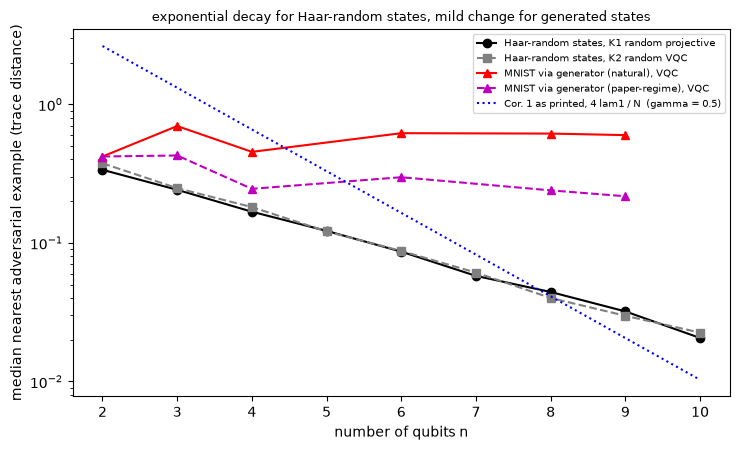

In [40]:
# ---------------- one figure that sums up the paper's message ----------------
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4.6))
ns_h = np.array(HAAR_QUBITS)
for nm, st in zip(names, ("ko-", "s--")):
    ax.semilogy(ns_h, [np.median(haar[(n, nm)]["eps_in"]) for n in ns_h], st, color="k" if nm == names[0] else "gray", label=f"Haar-random states, {nm}")
for variant, st in zip(VARIANTS, ("r^-", "m^--")):
    ax.semilogy(NS, [np.median(RES[(n, variant, "VQC")]["atk"]["eps_in"]) for n in NS], st, label=f"MNIST via generator ({variant}), VQC")
ax.semilogy(ns_h, [bound_printed(0.5, 2 ** n) for n in ns_h], "b:", label="Cor. 1 as printed, 4 lam1 / N  (gamma = 0.5)")
ax.set_xlabel("number of qubits n"); ax.set_ylabel("median nearest adversarial example (trace distance)"); ax.legend(fontsize=7)
ax.set_title("exponential decay for Haar-random states, mild change for generated states", fontsize=9)
plt.tight_layout(); plt.show()

## Reading the paper critically

*What this verification supports.*

1. **The Haar half of the story is real, but its printed rate is off.** Every classifier tried is exponentially vulnerable on Haar-random states (the median nearest adversarial example scales like `2^(-n/2)`, with the same curve for a Haar-random measurement and for a circuit), which is the concentration-of-measure phenomenon.
   The printed constant `d^-n` of Corollary 1 does not hold as a necessary condition once `N` is large; the proof converts a Hilbert-Schmidt bound into a trace-norm bound with an inequality that fails for `N >= 4` (Part A). The translated bound `4 lambda_1 / sqrt(N)` holds with a large margin.
2. **The generated-state half is supported, with caveats.** For states drawn from a Gaussian-latent generator the in-distribution risk satisfies the Gaussian isoperimetric floor in every case, the rigorous-modulus form of Theorem 2 holds, and the robustness changes far more slowly with `n` than for Haar-random states (see the table above for the exact numbers).
3. **Proposition 1 and Appendix B hold** (up to the factor 2 that the statement of Proposition 1 drops relative to its proof); Theorem 3's chain (H1) holds on all small instances tried.

*What the paper does not show, and this notebook only partly shows.*

* **No real model is attacked in the paper.** The "benign scaling" is an upper bound `omega(sqrt(ln(pi/2 gamma^2)))` on the robustness, "usually not tight" in the authors' own words. A bound that says robustness is *at most* `1/sqrt(n)` cannot, by itself, certify that a trained quantum classifier *is* robust: it only removes the exponential obstruction.
  The measurements here are a first step: trained VQCs on real digits sit below the bound and far above the Haar curve, but they are one small experiment (two digits, `n <= 8` pixels).
* **The `omega_1 = Omega(1)` hypothesis matters.** With a natural generator the `l1`-sensitivity `||L||_{2->1}` grows with the number of pixels; the pixel-by-pixel Hilbert-space distance then does *not* shrink as `1/sqrt(n)`. The "paper-regime" generator, which keeps the sensitivity fixed, is the regime the claim is about.
* **The classical baselines are as robust (or as fragile) as the VQC** on these inputs. The latent-space robustness is set by the geometry of the data and the Gaussian isoperimetric inequality, which is classifier-independent: that is the paper's own point, and it also means that Theorem 2 gives no quantum advantage in robustness.
* **Unconstrained attacks (Theorem 3).** The guaranteed lower bound is orders of magnitude below what an attacker achieves, as the authors note; the defence's cost (tomography of every qubit) is not accounted for.
* **Approximations of this notebook.** The attack estimates `eps_in` from above (every adversarial example found is a valid one, the true minimum can only be smaller); a violation of a bound by these estimates would therefore need a closer look, while a pass is conservative.
  A pooled-pixel PCA decoder is a crude "generator" (it produces blurry non-digits); no GAN or flow is trained.

## Exercises

1. **Higher qubit counts for Part A.** Set `FAST_MODE = False` (qubits 2 to 10). Is the fitted decay rate per qubit still `0.5`? Fit `ln(median eps_in)` against `n` using only `n >= 6`.
2. **Another classifier.** Replace the random VQC by one trained to separate two *real* state families (e.g. low-energy and high-energy states of a small spin chain). Does the median distance to the boundary still collapse onto `N^(-1/2)` when evaluated on Haar states, and what does it do on the training families?
3. **Another digit pair.** Change `DIGITS` to `(3, 8)`. Which of the three models loses most accuracy, and how does the median `eps_in` change relative to Part B?
4. **Non-linear class boundaries.** Replace the median threshold by a classifier with 5 equiprobable classes (use all digits with `K = 5`). Compare the empirical latent risk with the `K >= 5` bound (Eq. G3) that this notebook marks "cannot be checked".
5. **Qudits.** Extend `product_states` and Proposition 1's bound to `d = 3` (Eq. 2) and test the claim that the robustness increases with `d`.